# IND8217E – Final Project: Remaining Useful Life of Industrial Filters
**Dataset:** *Preventive to Predictive Maintenance* (Hagmeyer, Mauthe, Dutt & Zeiler, Hochschule Esslingen, 2021)

**Authors:** Bruno Albino Bennertz (2557056) · Rodrigo Fortunato Carvalho (2557001)

This notebook contains **all** the code used in the project: exploratory data analysis (EDA), data cleaning,
feature engineering, the construction of training labels from right-censored data, a reliability baseline, two
direct machine-learning RUL regressors, a recursive autoregressive model, and the final comparison on the unseen
test set. Every figure is saved to `figures/` and every
number quoted in the report is exported to `results/numbers.json` by the last cell.

| Section | Content |
|---|---|
| 0 | Setup |
| 1 | Problem definition |
| 2 | Data loading |
| 3 | Exploratory data analysis (variables, missing data, distributions, degradation, censoring) |
| 4 | Outliers, data cleaning and feature engineering |
| 5 | Training labels for censored runs (physics-based pseudo-labels) |
| 6 | Model 1 – Weibull AFT survival regression |
| 7 | Model 2 – Random forest on condition features |
| 8 | Model 3 – XGBoost on condition features |
| 9 | Model 4 – Recursive autoregressive model (no RUL labels) |
| 10 | Test-set comparison and maintenance policy |
| 11 | Hypotheses and export |

## 0. Setup

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
from scipy.special import gammaincc, gamma
from lifelines import WeibullAFTFitter, KaplanMeierFitter
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import xgboost
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", palette="deep", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 10})
PAL = sns.color_palette("deep")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

FAIL_DP = 600.0                                    # failure threshold on differential pressure [Pa]
RHO = {"A2": 0.900, "A3": 1.025, "A4": 1.200}      # bulk density of the test dusts [g/cm3] (dataset PDF)
DUST_NAME = {"A2": "A2 Fine", "A3": "A3 Medium", "A4": "A4 Coarse"}
DUST_COL = {"A2": PAL[0], "A3": PAL[1], "A4": PAL[2]}
MODEL_COL = {"M1 Weibull AFT": PAL[7], "M2 Random forest": PAL[2], "M3 XGBoost": PAL[0], "M4 Autoregressive": PAL[3]}
SET_PAL = {"train": PAL[0], "test": PAL[3]}
NUM = {}                                           # every number used in the report goes here

def savefig(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

print("xgboost", xgboost.__version__, "| pandas", pd.__version__, "| seaborn", sns.__version__)

xgboost 3.4.1 | pandas 2.3.3 | seaborn 0.13.2


## 1. Problem definition

A test bench loads a non-woven filter mat (CC 600 G) with Arizona test dust (ISO 12103-1, grades A2 fine, A3 medium,
A4 coarse). As particles accumulate the **differential pressure Δp** across the filter rises; the filter is
considered **failed when Δp exceeds 600 Pa**. All tests run under **flow control**, the dust feed rate is constant within a run.

The company currently uses **preventive maintenance**: filters are replaced after a fixed interval, chosen so that
only the shortest ~10 % of lives fail before replacement. Consequently the training data are mostly **right-censored**
(the filter was removed before it failed). The goal is to move to **predictive maintenance**: predict the
**remaining useful life (RUL, in seconds)** of a running filter from its condition data.

* **Problem type:** prognosis → supervised **regression** of RUL, with survival (censored) data.
* **Training set:** 50 runs recorded until the preventive replacement (censored, only a few reach 600 Pa).
* **Test set:** 50 complete run-to-failure tests, truncated at a random point; the true RUL is given as ground truth.
* **Evaluation:** only on the test set, which is never used for fitting or model selection.

## 2. Data loading

In [2]:
train_raw = pd.read_csv("data/Train_Data_CSV.csv")
test_raw = pd.read_csv("data/Test_Data_CSV.csv")
for df in (train_raw, test_raw):
    df["DustCode"] = df["Dust"].str.extract(r"(A\d)", expand=False)

print("Train:", train_raw.shape, "| Test:", test_raw.shape)
print("Runs  train:", train_raw.Data_No.nunique(), "| test:", test_raw.Data_No.nunique())
display(train_raw.head())
display(test_raw.head())
print(train_raw.dtypes)
NUM["n_rows_train"], NUM["n_rows_test"] = len(train_raw), len(test_raw)
NUM["n_runs_train"], NUM["n_runs_test"] = int(train_raw.Data_No.nunique()), int(test_raw.Data_No.nunique())

Train: (39420, 7) | Test: (39414, 8)
Runs  train: 50 | test: 50


,Data_No,Differential_pressure,Flow_rate,Time,Dust_feed,Dust,DustCode
0,1,0.0,0.0,0.1,236.428943,"ISO 12103-1, A3 Medium Test Dust",A3
1,1,0.0,0.0,0.2,236.428943,"ISO 12103-1, A3 Medium Test Dust",A3
2,1,0.0,0.0,0.3,236.428943,"ISO 12103-1, A3 Medium Test Dust",A3
3,1,0.0,0.0,0.4,236.428943,"ISO 12103-1, A3 Medium Test Dust",A3
4,1,0.0,0.0,0.5,236.428943,"ISO 12103-1, A3 Medium Test Dust",A3


,Data_No,Differential_pressure,Flow_rate,Time,Dust_feed,Dust,RUL,DustCode
0,1,0.271267,52.281993,0.1,236.428943,"ISO 12103-1, A3 Medium Test Dust",58.9,A3
1,1,0.361690,54.986671,0.2,236.428943,"ISO 12103-1, A3 Medium Test Dust",58.8,A3
2,1,0.000000,55.424786,0.3,236.428943,"ISO 12103-1, A3 Medium Test Dust",58.7,A3
3,1,2.622251,55.524146,0.4,236.428943,"ISO 12103-1, A3 Medium Test Dust",58.6,A3
4,1,3.888165,55.852018,0.5,236.428943,"ISO 12103-1, A3 Medium Test Dust",58.5,A3


Data_No                    int64
Differential_pressure    float64
Flow_rate                float64
Time                     float64
Dust_feed                float64
Dust                      object
DustCode                  object
dtype: object


## 3. Exploratory data analysis

### 3.1 Variable dictionary
Each row of the CSV files is one sample (10 Hz) of one life test (`Data_No`). The table below describes every
variable, its physical meaning and its role. Following the course workflow, variables are categorised as
**dependent ("response") vs independent ("state")** and **controllable ("settings") vs non-controllable
("sensory measurements")**.

In [3]:
def rng(col):
    out = []
    for d in (train_raw, test_raw):
        if col in d and pd.api.types.is_numeric_dtype(d[col]):
            out.append(f"{d[col].min():.4g} – {d[col].max():.4g}")
        elif col in d:
            out.append(", ".join(sorted(d[col].unique())))
        else:
            out.append("not available")
    return out

rows = [
 ("Data_No", "integer (ID)", "–", "Identifier of the life test (run)", "Grouping key", "–"),
 ("Time", "continuous", "s", "Elapsed time since the start of the run (10 Hz sampling)", "Independent (state)", "Non-controllable"),
 ("Differential_pressure", "continuous", "Pa", "Pressure drop across the filter = health indicator; failure at 600 Pa", "Dependent (response)", "Non-controllable (sensor, 0–2500 Pa)"),
 ("Flow_rate", "continuous", "not stated (≈ L/min)", "Air flow through the filter, corrected for the dust feed; set-point of the flow controller", "Independent (state)", "Controllable (setting, measured)"),
 ("Dust_feed", "continuous, 8 levels", "mm³/s", "Volume of dust injected per second, constant within a run", "Independent (state)", "Controllable (setting)"),
 ("Dust", "categorical, 3 levels", "–", "ISO 12103-1 test dust grade (A2 fine, A3 medium, A4 coarse)", "Independent (state)", "Controllable (setting)"),
 ("RUL", "continuous", "s", "Remaining useful life at each sample (ground truth, test only)", "Dependent (target)", "–"),
]
var_table = pd.DataFrame(rows, columns=["Variable", "Type", "Unit", "Physical meaning", "Dependency", "Controllability"])
var_table["Range train"] = [rng(c)[0] for c in var_table.Variable]
var_table["Range test"] = [rng(c)[1] for c in var_table.Variable]
var_table.to_csv("results/variable_table.csv", index=False)
display(var_table)

,Variable,Type,Unit,Physical meaning,Dependency,Controllability,Range train,Range test
0,Data_No,integer (ID),–,Identifier of the life test (run),Grouping key,–,1 – 50,1 – 50
1,Time,continuous,s,Elapsed time since the start of the run (10 Hz...,Independent (state),Non-controllable,0.1 – 179.4,0.1 – 258.1
2,Differential_pressure,continuous,Pa,Pressure drop across the filter = health indic...,Dependent (response),"Non-controllable (sensor, 0–2500 Pa)",0 – 607.9,0 – 575
3,Flow_rate,continuous,not stated (≈ L/min),"Air flow through the filter, corrected for the...",Independent (state),"Controllable (setting, measured)",0 – 84.2,0 – 84.24
4,Dust_feed,"continuous, 8 levels",mm³/s,"Volume of dust injected per second, constant w...",Independent (state),Controllable (setting),59.11 – 317,59.11 – 317
5,Dust,"categorical, 3 levels",–,"ISO 12103-1 test dust grade (A2 fine, A3 mediu...",Independent (state),Controllable (setting),"ISO 12103-1, A2 Fine Test Dust, ISO 12103-1, A...","ISO 12103-1, A2 Fine Test Dust, ISO 12103-1, A..."
6,RUL,continuous,s,Remaining useful life at each sample (ground t...,Dependent (target),–,not available,1.9 – 335.1


**Reading of the table**
* `Differential_pressure` is the only true *sensor* signal describing the filter condition; RUL is a function of its
  future trajectory. It is the response variable of the degradation process.
* `Dust_feed`, `Dust` and `Flow_rate` are the **operating settings** chosen before each test. They determine *how fast*
  the filter clogs. `Flow_rate` is controlled but measured, so it contains sensor noise and dropouts.
* `Time` is the clock. Combined with `Dust_feed` it gives the **cumulative volume of dust fed**
  `V = Dust_feed × Time` [mm³], a physically meaningful *load* variable that will be central in the analysis.
* The documented sampling frequency (`Sampling`, 10 Hz) is not a column of the CSV but is confirmed by the data
  (all time steps are 0.1 s).

### 3.2 Run-level view and design of experiments

In [4]:
def run_summary(df):
    g = df.groupby("Data_No")
    s = g.agg(n=("Time", "size"), t_end=("Time", "last"), dp_max=("Differential_pressure", "max"),
              feed=("Dust_feed", "first"), dust=("DustCode", "first"), flow=("Flow_rate", "median"))
    s["V_end"] = s.feed * s.t_end
    s["flow_level"] = np.where(s.flow > 70, "high (~81)", "low (~58)")
    return s

sum_tr, sum_te = run_summary(train_raw), run_summary(test_raw)
sum_tr["failed"] = sum_tr.dp_max >= FAIL_DP
sum_te["RUL_last"] = test_raw.groupby("Data_No").RUL.last()
display(sum_tr.head(10))
print("Train runs that reached 600 Pa:", list(sum_tr.index[sum_tr.failed]))

design = pd.concat({"train": pd.crosstab(sum_tr.feed.round(1), sum_tr.dust),
                    "test": pd.crosstab(sum_te.feed.round(1), sum_te.dust)}, axis=1).fillna(0).astype(int)
print("Number of runs per (dust feed, dust grade):")
display(design)
display(pd.concat({"train": sum_tr.groupby(["dust", "flow_level"]).size(),
                   "test": sum_te.groupby(["dust", "flow_level"]).size()}, axis=1).fillna(0).astype(int))
NUM["n_failed_train"] = int(sum_tr.failed.sum()); NUM["failed_runs"] = [int(i) for i in sum_tr.index[sum_tr.failed]]
NUM["feed_levels"] = sorted(set(np.round(sum_tr.feed, 1)) | set(np.round(sum_te.feed, 1)))

,n,t_end,dp_max,feed,dust,flow,V_end,flow_level,failed
Data_No,,,,,,,,,
1,449,44.9,230.4868,236.428943,A3,55.080360,10615.659550,low (~58),False
2,449,44.9,196.6688,236.428943,A3,56.259356,10615.659550,low (~58),False
3,449,44.9,355.9028,236.428943,A3,55.981171,10615.659550,low (~58),False
4,897,89.7,230.1252,118.214472,A3,81.145197,10603.838102,high (~81),False
5,897,89.7,367.2056,118.214472,A3,81.652482,10603.838102,high (~81),False
6,897,89.7,355.9028,118.214472,A3,81.737035,10603.838102,high (~81),False
7,1794,179.4,314.9414,59.107236,A3,81.660941,10603.838102,high (~81),False
8,1794,179.4,589.8257,59.107236,A2,81.111374,10603.838102,high (~81),False
9,669,66.9,330.7653,158.492533,A2,57.832988,10603.150428,low (~58),False


Train runs that reached 600 Pa: [11, 43, 44, 46, 47]
Number of runs per (dust feed, dust grade):


train       test      
dust     A2 A3 A4   A2 A3 A4
feed                        
59.1      2  1  1    2  2  4
79.2      3  2  1    0  3  1
118.2     2  5  1    0  3  1
158.5     4  9  3    0  8  1
177.3     0  1  2    3  1  1
236.4     0  3  2    3  2  1
237.7     0  3  2    3  2  1
317.0     0  2  1    3  3  2

train  test
dust flow_level             
A2   high (~81)      4     8
     low (~58)       7     6
A3   high (~81)     12     6
     low (~58)      14    18
A4   low (~58)      13     0
     high (~81)      0    12

The experiment is a (partial) factorial design: 3 dust grades × 8 feed levels × 2 flow levels (≈58 and ≈81).
Train and test cover the same settings and a similar mix of dust grades, but the test set contains more high-flow runs
(26 vs 16 of 50) and a higher average feed rate (179 vs 161 mm³/s): a mild **distribution shift** to keep in mind.

### 3.3 Missing data – explicit and implicit

In [5]:
explicit = pd.DataFrame({"NaN train": train_raw.isna().sum(), "NaN test": test_raw.reindex(columns=train_raw.columns.union(["RUL"])).isna().sum()})
display(explicit)

def implicit_checks(df, name, summ):
    d = df.copy()
    dt = d.groupby("Data_No").Time.diff()
    nxt = d.groupby("Data_No").Time.shift(-1)
    out = {
        "NaN cells": int(d.isna().sum().sum()),
        "duplicated rows": int(d.duplicated().sum()),
        "time gaps > 0.1 s (missing samples)": int((dt > 0.1501).sum()),
        "non-monotonic timestamps": int((nxt < d.Time).sum()),
        "runs not starting at t = 0.1 s": int((d.groupby("Data_No").Time.min() > 0.1001).sum()),
        "Δp == 0 rows (sensor dead-band)": int((d.Differential_pressure == 0).sum()),
        "Δp == 0 rows after t > 30 s": int(((d.Differential_pressure == 0) & (d.Time > 30)).sum()),
        "Flow_rate == 0 rows (dropouts)": int((d.Flow_rate <= 0).sum()),
        "runs with Flow_rate dropouts": int(d[d.Flow_rate <= 0].Data_No.nunique()),
        "Δp outside sensor range [0, 2500]": int(((d.Differential_pressure < 0) | (d.Differential_pressure > 2500)).sum()),
        "runs without observed failure (censored/truncated)": int((summ.dp_max < FAIL_DP).sum()),
    }
    return pd.Series(out, name=name)

miss = pd.concat([implicit_checks(train_raw, "train", sum_tr), implicit_checks(test_raw, "test", sum_te)], axis=1)
miss.to_csv("results/missing_data.csv"); display(miss)
NUM["missing"] = miss.to_dict()
bad = train_raw[train_raw.groupby("Data_No").Time.shift(-1) < train_raw.Time]
print("Corrupted timestamp row(s):"); display(bad)
print("Runs with flow dropouts (train):", sorted(train_raw[train_raw.Flow_rate <= 0].Data_No.unique()))
print("Runs with flow dropouts (test):", sorted(test_raw[test_raw.Flow_rate <= 0].Data_No.unique()))
z = train_raw[train_raw.Differential_pressure == 0]
print(f"Zero-Δp rows: median time = {z.Time.median():.1f} s, 95th percentile = {z.Time.quantile(.95):.1f} s")
NUM["zero_dp_median_t"] = float(z.Time.median()); NUM["zero_dp_p95_t"] = float(z.Time.quantile(.95))

,NaN train,NaN test
Data_No,0.0,0
Differential_pressure,0.0,0
Dust,0.0,0
DustCode,0.0,0
Dust_feed,0.0,0
Flow_rate,0.0,0
RUL,NaN,0
Time,0.0,0


,train,test
NaN cells,0,0
duplicated rows,0,0
time gaps > 0.1 s (missing samples),0,0
non-monotonic timestamps,1,0
runs not starting at t = 0.1 s,3,9
Δp == 0 rows (sensor dead-band),5672,2722
Δp == 0 rows after t > 30 s,556,116
Flow_rate == 0 rows (dropouts),45,13
runs with Flow_rate dropouts,8,13
"Δp outside sensor range [0, 2500]",0,0


Corrupted timestamp row(s):


,Data_No,Differential_pressure,Flow_rate,Time,Dust_feed,Dust,DustCode
21194,28,0.0,0.0,157.2,177.321707,"ISO 12103-1, A3 Medium Test Dust",A3


Runs with flow dropouts (train): [np.int64(1), np.int64(3), np.int64(14), np.int64(28), np.int64(31), np.int64(35), np.int64(36), np.int64(39)]
Runs with flow dropouts (test): [np.int64(9), np.int64(11), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(23), np.int64(24), np.int64(26), np.int64(32), np.int64(40), np.int64(42), np.int64(50)]
Zero-Δp rows: median time = 10.4 s, 95th percentile = 40.5 s


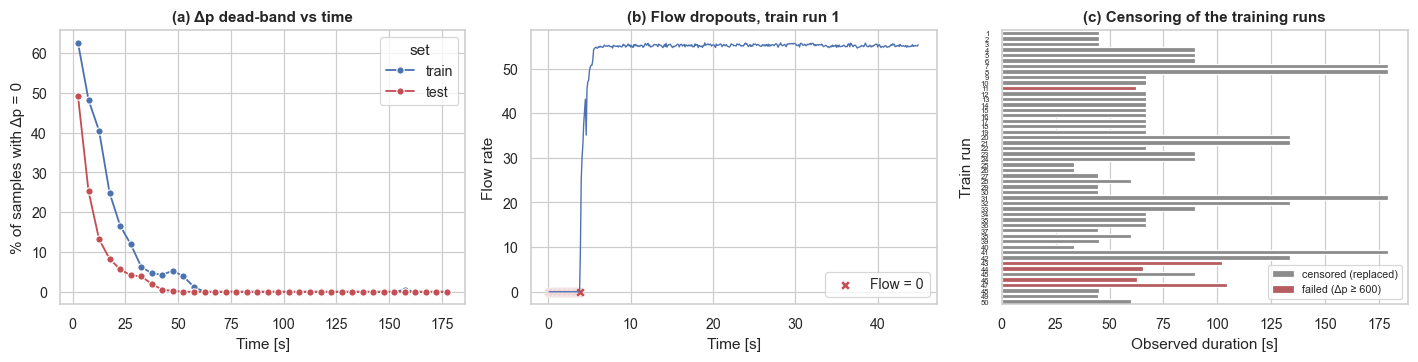

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
bins = np.arange(0, 181, 5)
zz = pd.concat([d.assign(b=pd.cut(d.Time, bins, labels=bins[:-1] + 2.5)).groupby("b", observed=False).Differential_pressure
                 .apply(lambda s: (s == 0).mean() * 100).rename("zero_pct").reset_index().assign(set=lab)
                for d, lab in [(train_raw, "train"), (test_raw, "test")]])
zz["b"] = zz.b.astype(float)
sns.lineplot(data=zz, x="b", y="zero_pct", hue="set", palette=SET_PAL, marker="o", ax=ax[0])
ax[0].set(xlabel="Time [s]", ylabel="% of samples with Δp = 0", title="(a) Δp dead-band vs time")
r = 1
d1 = train_raw[train_raw.Data_No == r]
sns.lineplot(data=d1, x="Time", y="Flow_rate", lw=.9, ax=ax[1], color=PAL[0])
sns.scatterplot(data=d1[d1.Flow_rate <= 0], x="Time", y="Flow_rate", marker="X", s=40, color=PAL[3], label="Flow = 0", ax=ax[1])
ax[1].set(xlabel="Time [s]", ylabel="Flow rate", title=f"(b) Flow dropouts, train run {r}")
cens = sum_tr.reset_index().assign(status=np.where(sum_tr.failed.values, "failed (Δp ≥ 600)", "censored (replaced)"))
cens["run"] = cens.Data_No.astype(str)
sns.barplot(data=cens, y="run", x="t_end", hue="status", dodge=False, orient="h", ax=ax[2],
            palette={"censored (replaced)": PAL[7], "failed (Δp ≥ 600)": PAL[3]})
ax[2].tick_params(axis="y", labelsize=5); ax[2].legend(fontsize=7)
ax[2].set(xlabel="Observed duration [s]", ylabel="Train run", title="(c) Censoring of the training runs")
plt.tight_layout(); savefig("fig01_missing_data"); plt.show()

**What is missing and why it matters**

| # | Issue | Size | Interpretation | Treatment (Section 4/5) |
|---|---|---|---|---|
| 1 | **Right-censoring** – failure time unknown | 45 of 50 train runs | Filters removed by the preventive policy before failure. This is the *main* missing information: the target (RUL) does not exist for most training samples. | Pseudo-labels from physics-based extrapolation, validated on the 5 failed runs; survival model that uses censoring natively |
| 2 | Δp = 0 readings | ~14 % train, ~7 % test rows | Concentrated in the first ~20 s: a clean filter produces only ~25 Pa, inside the sensor's dead-band. Not true zeros, but values below resolution. | Kept (they are informative: "filter still clean"), smoothed |
| 3 | Flow-rate dropouts (= 0) | 45 train / 13 test rows | Short sensor dropouts/transients (flow is controlled, cannot really be 0 while Δp keeps rising) | Treated as missing → linear interpolation within the run |
| 4 | Corrupted timestamp | 1 row (train run 28) | First row has Time = 157.2 s followed by 0.2 s | Row removed |
| 5 | Missing first sample | runs starting at 0.2 s | One sample lost at start | No action (0.1 s offset is negligible) |
| 6 | Test runs truncated | 50 test runs | By design: the future is what we must predict | This *is* the prediction task |

No explicit `NaN`, no duplicated rows and no gaps in the 10 Hz time grid were found.

### 3.4 Distributions

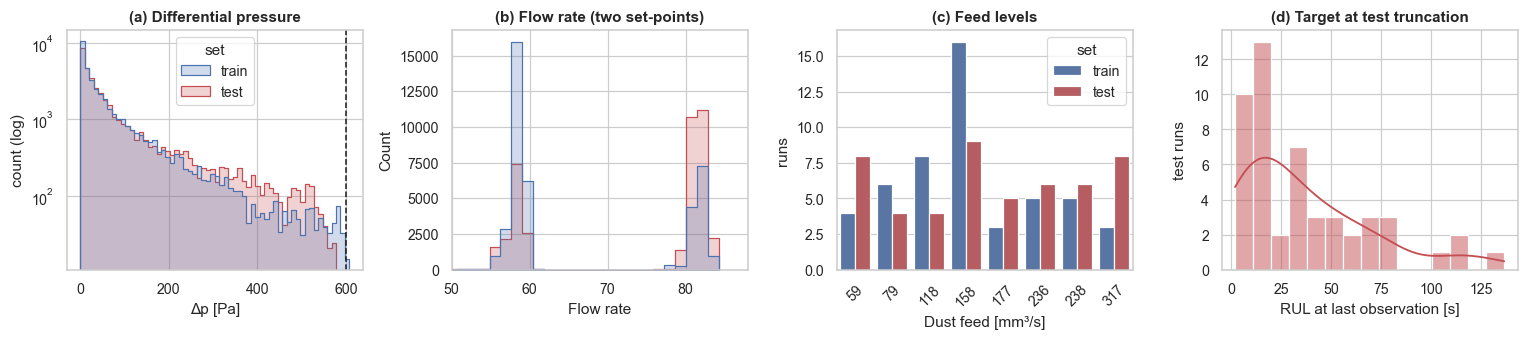

count        mean         std        min        25%         50%         75%         max
train Data_No                39420.0   25.167453   14.315149   1.000000  12.000000   24.000000   38.000000   50.000000
      Differential_pressure  39420.0   78.232050  107.342894   0.000000   8.590133   35.174340  102.358200  607.910200
      Flow_rate              39420.0   66.095780   11.306582   0.000000  58.458498   59.040107   81.136739   84.199355
      Time                   39420.0   49.135490   39.088269   0.100000  19.800000   39.900000   65.800000  179.400000
      Dust_feed              39420.0  132.247854   62.716754  59.107236  79.246266  118.214472  158.492533  316.985065
test  Data_No                39414.0   24.448775   12.689146   1.000000  15.000000   24.000000   31.000000   50.000000
      Differential_pressure  39414.0   93.204439  120.463934   0.000000  12.478300   41.503910  123.878800  574.996400
      Flow_rate              39414.0   73.172012   11.400250   0.000000  58.634074   80.717290   81.711670   84.244737
      Time                   39414.0   67.377812   61.810131   0.100000  19.900000   45.900000   99.100000  258.100000
      Dust_feed              39414.0  126.295097   80.632092  59.107236  59.107236   79.246266  158.492533  316.985065
      RUL                    39414.0  111.489605   74.140618   1.900000  50.500000   93.500000  163.700000  335.100000

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
both = pd.concat([train_raw.assign(set="train"), test_raw.assign(set="test")], ignore_index=True)
sns.histplot(data=both, x="Differential_pressure", hue="set", bins=60, element="step", palette=SET_PAL, ax=ax[0])
ax[0].set_yscale("log"); ax[0].axvline(FAIL_DP, color="k", ls="--", lw=1)
ax[0].set(xlabel="Δp [Pa]", ylabel="count (log)", title="(a) Differential pressure")
sns.histplot(data=both[both.Flow_rate > 0], x="Flow_rate", hue="set", bins=60, element="step", palette=SET_PAL, ax=ax[1], legend=False)
ax[1].set(xlabel="Flow rate", title="(b) Flow rate (two set-points)", xlim=(50, 88))
runs_both = pd.concat([sum_tr.assign(set="train"), sum_te.assign(set="test")])
runs_both["feed_lvl"] = runs_both.feed.round(0).astype(int).astype(str)
order = [str(int(round(v))) for v in sorted(NUM["feed_levels"])]
sns.countplot(data=runs_both, x="feed_lvl", hue="set", order=order, palette=SET_PAL, ax=ax[2])
ax[2].tick_params(axis="x", rotation=45); ax[2].set(xlabel="Dust feed [mm³/s]", ylabel="runs", title="(c) Feed levels")
sns.histplot(sum_te.RUL_last, bins=15, kde=True, color=PAL[3], ax=ax[3])
ax[3].set(xlabel="RUL at last observation [s]", ylabel="test runs", title="(d) Target at test truncation")
plt.tight_layout(); savefig("fig02_distributions"); plt.show()
display(pd.concat({"train": train_raw.describe().T, "test": test_raw.describe().T}))
NUM["rul_last_test"] = sum_te.RUL_last.describe().round(2).to_dict()

* **Δp** is strongly right-skewed: most samples come from the early, flat part of the curve; values near 600 Pa are rare
  (only the 5 failed training runs reach them; the test max is < 600 because test runs are truncated).
* **Flow rate** is bimodal: two set-points (≈58 and ≈81). It behaves as a categorical setting.
* **Feed** takes 8 discrete values between 59 and 317 mm³/s.
* The **test target** (RUL at the last observed sample) ranges from 1.9 to 136.6 s: the models must work both close
  to failure and far from it.

### 3.5 Degradation behaviour

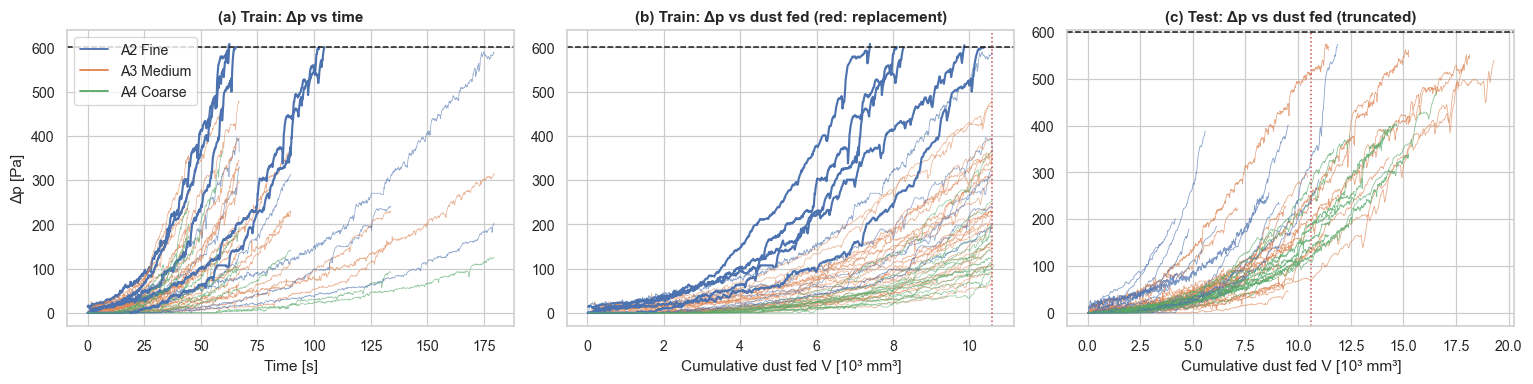

Preventive replacement happens at a constant dust volume: median V = 10604 mm³ (IQR 10603–10604)


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
plot_tr = train_raw[~(train_raw.groupby("Data_No").Time.shift(-1) < train_raw.Time)]   # hide the corrupted timestamp (see 3.3)
for r, d in plot_tr.groupby("Data_No"):
    c = DUST_COL[d.DustCode.iloc[0]]; f = sum_tr.loc[r, "failed"]
    ax[0].plot(d.Time, d.Differential_pressure, color=c, lw=1.4 if f else .5, alpha=1 if f else .6)
    ax[1].plot(d.Time * d.Dust_feed / 1000, d.Differential_pressure, color=c, lw=1.4 if f else .5, alpha=1 if f else .6)
for r, d in test_raw.groupby("Data_No"):
    ax[2].plot(d.Time * d.Dust_feed / 1000, d.Differential_pressure, color=DUST_COL[d.DustCode.iloc[0]], lw=.5, alpha=.7)
for a in ax: a.axhline(FAIL_DP, color="k", ls="--", lw=1)
Vc = float(np.median(sum_tr.loc[~sum_tr.failed, "V_end"]))
for a in ax[1:]: a.axvline(Vc / 1000, color="r", ls=":", lw=1)
ax[0].set(xlabel="Time [s]", ylabel="Δp [Pa]", title="(a) Train: Δp vs time")
ax[1].set(xlabel="Cumulative dust fed V [10³ mm³]", title="(b) Train: Δp vs dust fed (red: replacement)")
ax[2].set(xlabel="Cumulative dust fed V [10³ mm³]", title="(c) Test: Δp vs dust fed (truncated)")
for k, c in DUST_COL.items(): ax[0].plot([], [], color=c, label=DUST_NAME[k])
ax[0].legend(); plt.tight_layout(); savefig("fig03_degradation_curves"); plt.show()
NUM["V_censor"] = Vc
print(f"Preventive replacement happens at a constant dust volume: median V = {Vc:.0f} mm³ "
      f"(IQR {sum_tr.loc[~sum_tr.failed,'V_end'].quantile(.25):.0f}–{sum_tr.loc[~sum_tr.failed,'V_end'].quantile(.75):.0f})")

* Δp grows **slowly at first and then accelerates** (convex, close to exponential), as in Fig. 6 of the dataset
  documentation: first *depth filtration* (particles captured inside the fibres) and then *cake filtration*
  (a dust cake forms on the surface and the resistance grows quickly).
* Plotted against **time** the curves are spread out because feed rates differ by a factor of 5. Plotted against the
  **cumulative dust volume V** they collapse into a much narrower band: the load, not the clock, drives clogging.
* The preventive replacement happens at a **constant dust volume** (V ≈ 10 600 mm³), i.e. the replacement interval
  is inversely proportional to the feed rate, exactly as stated in the dataset description.
* Fine dust (A2) reaches high Δp for the same volume much faster than medium/coarse dust: small particles form a
  denser cake.

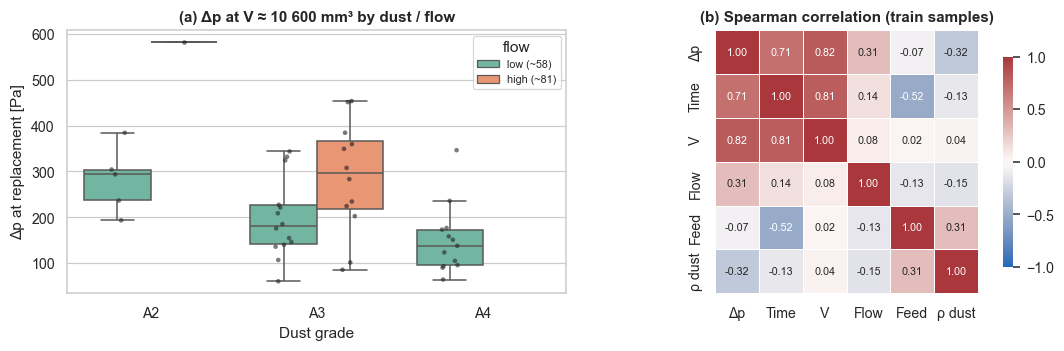

count   mean    std    min    25%    50%    75%    max
dust flow_level                                                        
A2   high (~81)    1.0  581.6    NaN  581.6  581.6  581.6  581.6  581.6
     low (~58)     5.0  282.4   72.5  193.3  236.6  293.6  304.2  384.4
A3   high (~81)   12.0  286.5  121.6   85.4  219.0  295.5  365.8  453.6
     low (~58)    14.0  197.3   86.1   60.4  141.6  180.5  225.8  343.6
A4   low (~58)    13.0  150.0   74.9   64.1   95.5  137.8  173.1  346.4

In [9]:
# Δp reached at the replacement volume, by dust grade and flow level (censored train runs only)
end_dp = sum_tr[~sum_tr.failed].assign(dp_end=train_raw.groupby("Data_No").Differential_pressure.apply(lambda s: s.iloc[-20:].mean()))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
grp = end_dp.groupby(["dust", "flow_level"]).dp_end
sns.boxplot(data=end_dp, x="dust", y="dp_end", hue="flow_level", order=["A2", "A3", "A4"], palette="Set2", ax=ax[0], fliersize=0)
sns.stripplot(data=end_dp, x="dust", y="dp_end", hue="flow_level", order=["A2", "A3", "A4"], dodge=True, palette="dark:k",
              size=3, alpha=.6, ax=ax[0], legend=False)
ax[0].set(xlabel="Dust grade", ylabel="Δp at replacement [Pa]", title="(a) Δp at V ≈ 10 600 mm³ by dust / flow")
ax[0].legend(title="flow", fontsize=7)
num = train_raw.assign(V=train_raw.Time * train_raw.Dust_feed, rho=train_raw.DustCode.map(RHO))[["Differential_pressure", "Time", "V", "Flow_rate", "Dust_feed", "rho"]]
corr = num.corr(method="spearman")
lbl = ["Δp", "Time", "V", "Flow", "Feed", "ρ dust"]
sns.heatmap(corr.set_axis(lbl).set_axis(lbl, axis=1), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True,
            linewidths=.5, cbar_kws={"shrink": .8}, annot_kws={"size": 7}, ax=ax[1])
ax[1].set_title("(b) Spearman correlation (train samples)")
plt.tight_layout(); savefig("fig04_settings_effect"); plt.show()
display(grp.describe().round(1))
NUM["dp_end_by_group"] = {f"{a}|{b}": round(float(v), 1) for (a, b), v in grp.median().items()}
NUM["spearman_dp"] = corr["Differential_pressure"].round(3).to_dict()

* At the same dust volume, **high flow** gives a much higher Δp than low flow (pressure drop ∝ flow velocity – Darcy's
  law), and **fine dust** gives the highest Δp. Flow and dust grade therefore change the *rate* of degradation.
* Δp correlates most strongly with the cumulative volume V (Spearman), more than with time alone.

### 3.6 Lifetime information contained in the training data

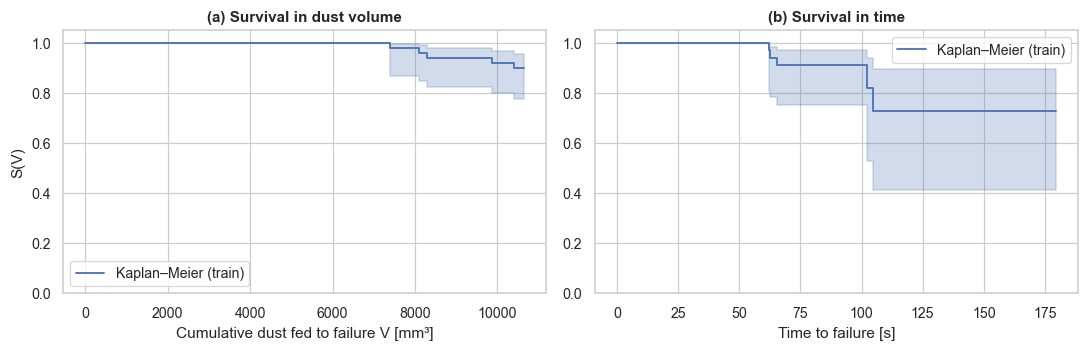

Failed train runs:


,n,t_end,dp_max,feed,dust,flow,V_end,flow_level,failed
Data_No,,,,,,,,,
11,623,62.3,604.9262,158.492533,A2,57.415961,9874.084778,low (~58),True
43,1022,102.2,601.0380,79.246266,A2,80.940781,8098.968414,high (~81),True
44,656,65.6,600.9476,158.492533,A2,82.848839,10397.110136,high (~81),True
46,626,62.6,607.9102,118.214472,A2,82.692427,7400.225922,high (~81),True
47,1046,104.6,600.2242,79.246266,A2,58.952319,8289.159453,low (~58),True


In [10]:
kmf = KaplanMeierFitter()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
kmf.fit(sum_tr.V_end, event_observed=sum_tr.failed, label="Kaplan–Meier (train)")
kmf.plot_survival_function(ax=ax[0]); ax[0].set(xlabel="Cumulative dust fed to failure V [mm³]", ylabel="S(V)", title="(a) Survival in dust volume", ylim=(0, 1.05))
kmf.fit(sum_tr.t_end, event_observed=sum_tr.failed, label="Kaplan–Meier (train)")
kmf.plot_survival_function(ax=ax[1]); ax[1].set(xlabel="Time to failure [s]", title="(b) Survival in time", ylim=(0, 1.05))
plt.tight_layout(); savefig("fig05_kaplan_meier"); plt.show()
print("Failed train runs:"); display(sum_tr[sum_tr.failed])

With 45/50 runs censored, the Kaplan–Meier estimate only drops to ≈0.9: the training data tell us **when 10 % of the
filters fail**, not how long a typical filter lives. Any model trained naively only on the five failures would be
heavily biased towards short lives; any model that treats the censoring time as the failure time would underestimate
life systematically. This motivates Section 5.

## 4. Data cleaning, outliers and feature engineering

### 4.1 Outlier analysis
Before cleaning, every variable is screened for outliers. Large Δp values close to 600 Pa are **not** outliers: they are
the failure signal itself, so a global rule such as the IQR rule (which would flag them) must not be used. Instead we
look for *local* anomalies inside each run:
* Δp outside the physical range of the sensor (0–2500 Pa);
* isolated Δp **spikes**: samples that deviate by more than 5 robust standard deviations (MAD) **and** more than 20 Pa
  from the median of the surrounding 1-s window (±0.5 s) of the same run (Hampel criterion);
* flow readings far (> 8 units) from the run's set-point, excluding the zero dropouts already discussed.

In [11]:
def outlier_report(df):
    d = df.copy(); g = d.groupby("Data_No")
    med = g.Differential_pressure.transform(lambda s: s.rolling(11, min_periods=1, center=True).median())
    res = (d.Differential_pressure - med).abs()
    mad = res.groupby(d.Data_No).transform(lambda s: 1.4826 * s.median() + 1e-9)
    setp = np.where(d.Flow_rate > 70, 81.5, 58.5)
    q1, q3 = d.Differential_pressure.quantile([.25, .75])
    return pd.Series({
        "Δp outside sensor range": int(((d.Differential_pressure < 0) | (d.Differential_pressure > 2500)).sum()),
        "Δp flagged by global IQR rule (NOT outliers: near-failure values)": int((d.Differential_pressure > q3 + 1.5 * (q3 - q1)).sum()),
        "Δp jumps > 50 Pa between consecutive samples": int((g.Differential_pressure.diff().abs() > 50).sum()),
        "Δp spikes (Hampel: > 5 MAD and > 20 Pa)": int(((res > 5 * mad) & (res > 20)).sum()),
        "Flow > 8 units from set-point (non-zero)": int((((d.Flow_rate - setp).abs() > 8) & (d.Flow_rate > 0)).sum()),
    })
out_tab = pd.concat({"train": outlier_report(train_raw), "test": outlier_report(test_raw)}, axis=1)
display(out_tab); NUM["outliers"] = out_tab.to_dict()
fl = train_raw[(train_raw.Flow_rate > 0)]
far = fl[(fl.Flow_rate - np.where(fl.Flow_rate > 70, 81.5, 58.5)).abs() > 8]
print(f"Off-set-point flow readings: median time {far.Time.median():.1f} s (start-up transients), in {far.Data_No.nunique()} train runs")
NUM["flow_offsetpoint_median_t"] = float(far.Time.median())

,train,test
Δp outside sensor range,0,0
Δp flagged by global IQR rule (NOT outliers: near-failure values),3292,3592
Δp jumps > 50 Pa between consecutive samples,0,0
Δp spikes (Hampel: > 5 MAD and > 20 Pa),17,28
Flow > 8 units from set-point (non-zero),104,84


Off-set-point flow readings: median time 0.2 s (start-up transients), in 47 train runs


**Decision on outliers.**
* No value is outside the sensor range and there are no physically impossible jumps (> 50 Pa in 0.1 s).
* The few isolated Δp spikes (a few tens of samples out of ~39 000 per set) are measurement noise: they are **replaced
  by the local median** (Hampel filter) instead of deleted, so the 10 Hz time grid stays intact. A centred window is
  used on purpose: a backward-looking window lags behind the fast rise of Δp near failure and would wrongly flag
  hundreds of legitimate samples. In an online deployment this only adds a 0.5 s latency. The raw value
  is kept in `dp_raw` and the failure time (first raw Δp ≥ 600 Pa) is always taken from the raw signal.
* Off-set-point flow readings are start-up transients of the flow controller; they are kept, because flow only enters
  the models through its running mean and the set-point indicator, which are robust to them.
* High Δp values are the phenomenon to predict and are never removed.

### 4.2 Cleaning and features
Cleaning (applied identically and independently to each run of train and test – no statistics are learned from test):
1. remove the corrupted timestamp row (a sample whose time is larger than the next sample's time);
2. treat `Flow_rate = 0` as missing and interpolate linearly within the run;
3. replace isolated Δp spikes by the local median (Hampel filter, see 4.1);
4. keep Δp dead-band zeros, but smooth Δp with a **causal** 1-s moving average (only past samples, so the
   feature can be computed online);
5. derive load variables: cumulative dust volume `V = feed·t` [mm³] and mass `m = V·ρ/1000` [g].

Condition features (all causal, computed at 10 Hz and then sampled at 1 Hz for modelling):

| Feature | Meaning |
|---|---|
| `dp_s`, `dp_frac` | smoothed Δp and Δp/600 (how close to failure) |
| `slope5`, `slope10` | Δp growth rate over the last 5 / 10 s [Pa/s] |
| `curv` | change of slope (acceleration of clogging) |
| `gr10` | growth rate of log Δp over 10 s (local exponential rate) |
| `Time`, `V`, `mass` | age of the filter in time and in dust load |
| `log_feed`, `rho`, `A3`, `A4` | dust feed (log) and dust grade (density + one-hot, A2 = reference) |
| `flow_s`, `flow_high` | running mean of flow and flow set-point indicator |

Removed corrupted rows: train 1 | test 0 || Hampel-replaced spikes: train 17 | test 28
Remaining flow NaN: 0 0


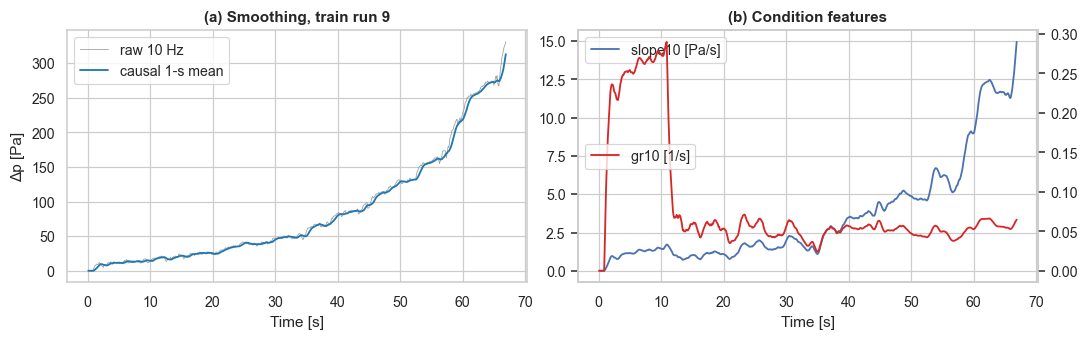

In [12]:
def clean(df):
    d = df.copy()
    bad = d.groupby("Data_No").Time.shift(-1) < d.Time          # corrupted (out-of-order) timestamp
    d = d[~bad].sort_values(["Data_No", "Time"]).reset_index(drop=True)
    d.loc[d.Flow_rate <= 0, "Flow_rate"] = np.nan
    d["Flow_rate"] = d.groupby("Data_No").Flow_rate.transform(lambda s: s.interpolate(limit_direction="both"))
    d["dp_raw"] = d.Differential_pressure                                # raw value kept (failure detection)
    med = d.groupby("Data_No").Differential_pressure.transform(lambda s: s.rolling(11, min_periods=1, center=True).median())
    res = (d.Differential_pressure - med).abs()
    mad = res.groupby(d.Data_No).transform(lambda s: 1.4826 * s.median() + 1e-9)
    spike = (res > 5 * mad) & (res > 20)
    d.loc[spike, "Differential_pressure"] = med[spike]                   # Hampel filter (centred 1-s window)
    return d, int(bad.sum()), int(spike.sum())

def lag(df, col, k):
    return df.groupby("Data_No")[col].transform(lambda s: s.shift(k).fillna(s.iloc[0]))

def add_features(d):
    d = d.copy()
    d["dp_s"] = d.groupby("Data_No").Differential_pressure.transform(lambda s: s.rolling(10, min_periods=1).mean())
    d["flow_s"] = d.groupby("Data_No").Flow_rate.transform(lambda s: s.expanding().mean())
    d["slope5"] = (d.dp_s - lag(d, "dp_s", 50)) / 5
    d["slope10"] = (d.dp_s - lag(d, "dp_s", 100)) / 10
    d["curv"] = d.slope5 - (lag(d, "dp_s", 50) - lag(d, "dp_s", 100)) / 5
    d["logdp"] = np.log1p(d.dp_s.clip(lower=0))
    d["gr10"] = (d.logdp - lag(d, "logdp", 100)) / 10
    d["logdp_l5"], d["logdp_l10"] = lag(d, "logdp", 50), lag(d, "logdp", 100)   # lags used by the autoregressive model
    d["dp_frac"] = d.dp_s / FAIL_DP
    d["V"] = d.Dust_feed * d.Time
    d["rho"] = d.DustCode.map(RHO)
    d["mass"] = d.V * d.rho / 1000
    d["log_feed"] = np.log(d.Dust_feed)
    d["A3"] = (d.DustCode == "A3").astype(int); d["A4"] = (d.DustCode == "A4").astype(int)
    d["flow_high"] = (d.flow_s > 70).astype(int)
    d["is_sec"] = (np.round(d.Time * 10).astype(int) % 10 == 0)
    d["is_last"] = d.groupby("Data_No").Time.transform("max") == d.Time
    return d

train_c, nbad_tr, nsp_tr = clean(train_raw); test_c, nbad_te, nsp_te = clean(test_raw)
train_f, test_f = add_features(train_c), add_features(test_c)
print("Removed corrupted rows: train", nbad_tr, "| test", nbad_te, "|| Hampel-replaced spikes: train", nsp_tr, "| test", nsp_te)
NUM["n_spikes"] = {"train": nsp_tr, "test": nsp_te}
print("Remaining flow NaN:", train_f.Flow_rate.isna().sum(), test_f.Flow_rate.isna().sum())

FEATS = ["dp_s", "dp_frac", "slope5", "slope10", "curv", "gr10", "Time", "V", "mass",
         "log_feed", "rho", "A3", "A4", "flow_s", "flow_high"]
r = 9
d = train_f[train_f.Data_No == r]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(d.Time, d.Differential_pressure, lw=.5, color="0.6", label="raw 10 Hz"); ax[0].plot(d.Time, d.dp_s, color="tab:blue", label="causal 1-s mean")
ax[0].set(xlabel="Time [s]", ylabel="Δp [Pa]", title=f"(a) Smoothing, train run {r}"); ax[0].legend()
ax[1].plot(d.Time, d.slope10, label="slope10 [Pa/s]"); ax2 = ax[1].twinx(); ax2.plot(d.Time, d.gr10, color="tab:red", label="gr10 [1/s]")
ax[1].set(xlabel="Time [s]", title="(b) Condition features"); ax[1].legend(loc="upper left"); ax2.legend(loc="center left"); ax2.grid(False)
plt.tight_layout(); savefig("fig06_features"); plt.show()
NUM["n_removed_rows"] = nbad_tr + nbad_te

## 5. Training labels for censored runs (physics-informed pseudo-labels)

The RUL of a training sample is `T_fail − t`. For the 5 failed runs `T_fail` is observed. For the 45 censored runs we
only know `T_fail > T_c`. We therefore **extrapolate the degradation curve** of each censored run to 600 Pa.

Candidate curve shapes (all fitted to the smoothed Δp of the run):
* **exponential** `Δp = a·e^{b t} + c` (clogging accelerates; at constant feed `t ∝ V`, so this is also exponential in dust load);
* quadratic `a + b t + c t²`;
* power law `a·t^b + c`;
* linear extrapolation of the last 20 % of the curve.

**Validation:** the 5 runs that actually failed are truncated at 30 %, 50 %, 70 % and 90 % of their life, the curve is
fitted to the truncated part only and the extrapolated failure time is compared with the true one.

In [13]:
def f_exp(x, a, b, c): return a * np.exp(b * x) + c
def f_pow(x, a, b, c): return a * np.power(x, b) + c

def time_to_threshold(x, y, form, thr=FAIL_DP):
    # Fit `form` to (x, y) and return the time at which the fitted curve reaches thr (NaN if it never does).
    if form == "exponential":
        b0 = 3.0 / max(x[-1], 1.0); a0 = max(y[-1] - y[0], 1.0) * np.exp(-b0 * x[-1])
        (a, b, c), _ = curve_fit(f_exp, x, y, p0=[a0, b0, max(y[0], 0)], bounds=([1e-9, 1e-5, -200], [1e4, 2, 590]), maxfev=20000)
        return np.log((thr - c) / a) / b if thr > c else np.nan
    if form == "quadratic":
        c2, c1, c0 = np.polyfit(x, y, 2); roots = np.roots([c2, c1, c0 - thr])
        roots = roots[np.isreal(roots)].real; roots = roots[roots > x[-1]]
        return roots.min() if len(roots) else np.nan
    if form == "power":
        (a, b, c), _ = curve_fit(f_pow, x, y, p0=[0.01, 2, 0], bounds=([1e-12, 0.5, -200], [1e4, 10, 590]), maxfev=20000)
        return ((thr - c) / a) ** (1 / b)
    if form == "linear tail":
        n = max(5, int(len(x) * 0.2)); s, i = np.polyfit(x[-n:], y[-n:], 1)
        return x[-1] + (thr - y[-1]) / s if s > 0 else np.nan

def centered(d):  # non-causal smoothing is allowed for building labels (whole run known)
    return d.Differential_pressure.rolling(10, min_periods=1, center=True).mean().values

FORMS = ["exponential", "quadratic", "power", "linear tail"]
FAILED = NUM["failed_runs"]
val = []
for r in FAILED:
    d = train_c[train_c.Data_No == r]; x = d.Time.values; y = centered(d)
    Tf = x[np.argmax(d.dp_raw.values >= FAIL_DP)]
    for frac in [0.3, 0.5, 0.7, 0.9]:
        m = (x <= frac * Tf)
        for fm in FORMS:
            try: Th = time_to_threshold(x[m][::10], y[m][::10], fm)
            except Exception: Th = np.nan
            val.append(dict(run=r, frac=frac, form=fm, T_fail=Tf, T_hat=Th, err_pct=(Th - Tf) / Tf * 100))
val = pd.DataFrame(val)
val_sum = val.groupby("form").err_pct.agg(rms=lambda e: np.sqrt(np.nanmean(e**2)), bias="mean", n_fail_to_fit=lambda e: e.isna().sum())
val_frac = val.pivot_table(index="frac", columns="form", values="err_pct", aggfunc=lambda e: np.sqrt(np.nanmean(e**2)))
val_bias = val.pivot_table(index="frac", columns="form", values="err_pct", aggfunc="mean")
print("Overall (all truncation fractions):"); display(val_sum.round(1))
print("RMS error [%] by observed fraction of life:"); display(val_frac.round(1))
print("Mean error (bias) [%] by observed fraction of life (negative = conservative):"); display(val_bias.round(1))
BEST_FORM = val_sum.rms.idxmin()
print("Selected curve form:", BEST_FORM)
NUM["label_val"] = val_sum.round(2).to_dict(); NUM["label_val_by_frac"] = val_frac.round(2).to_dict()
NUM["label_bias_by_frac"] = val_bias.round(2).to_dict(); NUM["best_form"] = BEST_FORM

Overall (all truncation fractions):


,rms,bias,n_fail_to_fit
form,,,
exponential,62.8,12.2,0
linear tail,161.5,101.4,0
power,231.8,90.1,0
quadratic,145.3,53.0,1


RMS error [%] by observed fraction of life:


form,exponential,linear tail,power,quadratic
frac,,,,
0.3,124.4,285.4,460.8,312.7
0.5,14.8,146.9,49.0,41.1
0.7,8.6,35.7,11.0,17.6
0.9,4.3,2.8,2.1,4.3


Mean error (bias) [%] by observed fraction of life (negative = conservative):


form,exponential,linear tail,power,quadratic
frac,,,,
0.3,64.2,257.9,322.4,190.0
0.5,-4.6,116.2,34.8,34.2
0.7,-6.5,30.6,4.8,12.7
0.9,-4.2,1.1,-1.7,2.4


Selected curve form: exponential


kind                observed failure pseudo-label                  
dust                              A2           A2       A3       A4
T_label       count              5.0          6.0     26.0     13.0
              mean              79.0        140.0     92.0     98.0
              std               22.0         65.0     42.0     62.0
              min               62.0         75.0     42.0     45.0
              25%               63.0         85.0     65.0     60.0
              50%               66.0        133.0     79.0     80.0
              75%              102.0        175.0    104.0     94.0
              max              105.0        239.0    216.0    259.0
V_label       count              5.0          6.0     26.0     13.0
              mean            8812.0      12387.0  13427.0  14115.0
              std             1266.0       1151.0   1380.0   1176.0
              min             7400.0      10610.0  11350.0  11775.0
              25%             8099.0      11997.0  12288.0  13263.0
              50%             8289.0      12455.0  13318.0  14144.0
              75%             9874.0      12743.0  14076.0  14913.0
              max            10397.0      14119.0  16571.0  16003.0
extension_pct count              5.0          6.0     26.0     13.0
              mean               0.0         17.0     27.0     33.0
              std                0.0         11.0     13.0     11.0
              min                0.0          0.0      7.0     11.0
              25%                0.0         13.0     16.0     25.0
              50%                0.0         17.0     26.0     33.0
              75%                0.0         20.0     33.0     41.0
              max                0.0         33.0     56.0     51.0

All pseudo-labels respect T_label >= T_c: True
Observed fraction of (pseudo) life in the censored runs: {'count': 45.0, 'mean': 0.79, 'std': 0.08, 'min': 0.64, '25%': 0.75, '50%': 0.79, '75%': 0.86, 'max': 1.0}


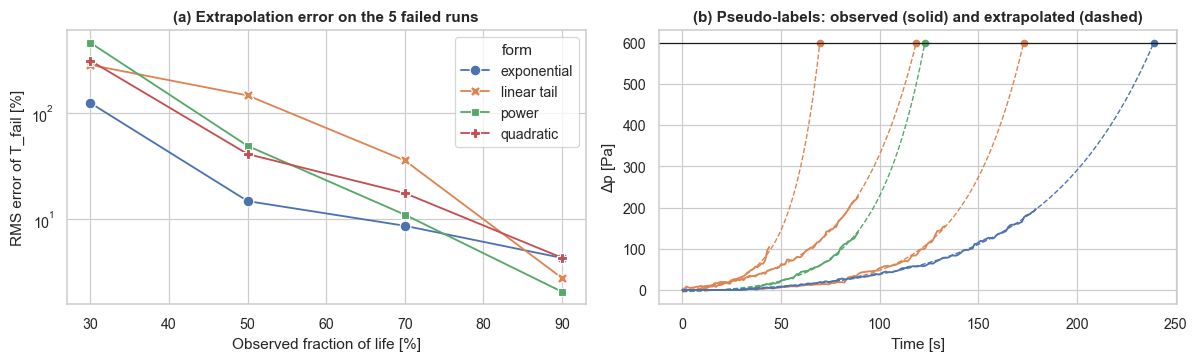

In [14]:
labels = []
for r, d in train_c.groupby("Data_No"):
    x = d.Time.values; y = centered(d); feed = d.Dust_feed.iloc[0]
    if d.dp_raw.max() >= FAIL_DP:
        T = x[np.argmax(d.dp_raw.values >= FAIL_DP)]; kind = "observed failure"
    else:
        try: T = time_to_threshold(x[::10], y[::10], BEST_FORM)
        except Exception: T = np.nan
        T = np.nanmax([T, x[-1] + 0.1]); kind = "pseudo-label"   # constraint: the filter survived until removal
    labels.append(dict(Data_No=r, T_label=T, kind=kind, T_obs=x[-1], feed=feed, dust=d.DustCode.iloc[0],
                       flow_level=sum_tr.loc[r, "flow_level"], V_label=T * feed))
labels = pd.DataFrame(labels).set_index("Data_No")
labels["extension_pct"] = (labels.T_label / labels.T_obs - 1) * 100
labels["observed_frac"] = labels.T_obs / labels.T_label
display(labels.groupby(["kind", "dust"])[["T_label", "V_label", "extension_pct"]].describe().round(0).T)
print("All pseudo-labels respect T_label >= T_c:", bool((labels.T_label >= labels.T_obs).all()))
NUM["pseudo_V_by_dust"] = labels[labels.kind == "pseudo-label"].groupby("dust").V_label.median().round(0).to_dict()
NUM["pseudo_ext_median"] = float(labels[labels.kind == "pseudo-label"].extension_pct.median())
NUM["pseudo_obs_frac"] = labels[labels.kind == "pseudo-label"].observed_frac.describe().round(3).to_dict()
print("Observed fraction of (pseudo) life in the censored runs:", labels[labels.kind == "pseudo-label"].observed_frac.describe().round(2).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
vv = val.groupby(["form", "frac"]).err_pct.apply(lambda e: np.sqrt(np.nanmean(e**2))).rename("rms").reset_index()
vv["frac"] = vv.frac * 100
sns.lineplot(data=vv, x="frac", y="rms", hue="form", style="form", markers=True, dashes=False, markersize=7, ax=ax[0])
ax[0].set(xlabel="Observed fraction of life [%]", ylabel="RMS error of T_fail [%]", title="(a) Extrapolation error on the 5 failed runs", yscale="log")
for r in [4, 20, 27, 33, 41]:
    d = train_c[train_c.Data_No == r]; x = d.Time.values[::10]; y = centered(d)[::10]
    (a, b, c), _ = curve_fit(f_exp, x, y, p0=[max(y[-1], 1) * np.exp(-3), 3 / x[-1], 0], bounds=([1e-9, 1e-5, -200], [1e4, 2, 590]), maxfev=20000)
    xx = np.linspace(0, labels.loc[r, "T_label"], 200); col = DUST_COL[d.DustCode.iloc[0]]
    ax[1].plot(x, y, color=col, lw=1.2); ax[1].plot(xx, f_exp(xx, a, b, c), "--", color=col, lw=.9)
    ax[1].plot(labels.loc[r, "T_label"], FAIL_DP, "o", color=col, ms=4)
ax[1].axhline(FAIL_DP, color="k", lw=.8); ax[1].set(xlabel="Time [s]", ylabel="Δp [Pa]", title="(b) Pseudo-labels: observed (solid) and extrapolated (dashed)")
plt.tight_layout(); savefig("fig07_pseudo_labels"); plt.show()

**Reading of the validation.** The exponential form has by far the smallest overall error and is the best when 30–70 % of
the life is observed (at 90 % all forms are within ~5 %). All
forms are unreliable when only 30 % of the life is observed (the curve is still flat), but from 50 % on the
exponential extrapolation is within roughly ±15 % and its bias is negative, i.e. it **under-estimates** the failure
time – the pseudo-labels are **conservative**, a safe direction for maintenance. The censored training runs have been
observed for most of their (pseudo-)life (see the observed-fraction statistics above), which is inside the reliable
range. The exponential model is therefore used to build the training labels of all models.

A further, important observation: **all five failed training runs use A2 fine dust.** The training data contain no
failure at all for medium (A3) or coarse (A4) dust; their lifetimes only enter through the pseudo-labels.

Training samples are taken at 1 Hz from every run; their label is `RUL = T_label − t`.

In [15]:
TR = train_f[train_f.is_sec & (train_f.Time >= 1)].copy()
TR = TR.join(labels[["T_label", "kind"]], on="Data_No")
TR["RUL"] = TR.T_label - TR.Time
TE = test_f[(test_f.is_sec & (test_f.Time >= 1)) | test_f.is_last].copy()      # evaluation grid (1 Hz + last sample)
print("Training samples:", len(TR), "| from failed runs:", int((TR.kind == "observed failure").sum()))
print("Test evaluation samples:", len(TE), "| last-sample points:", int(TE.is_last.sum()))
groups = TR.Data_No.values
gkf = GroupKFold(n_splits=5)
NUM["n_train_samples"], NUM["n_test_eval_samples"] = len(TR), len(TE)

Training samples: 3907 | from failed runs: 395
Test evaluation samples: 3963 | last-sample points: 50


## 6. Model 1 – Weibull accelerated-failure-time (AFT) regression

Classical reliability baseline, consistent with the Weibull/PHM models of the course. It uses **only the operating
settings** – no condition monitoring:

$$T \sim \text{Weibull}(\lambda(x), \rho), \qquad \log \lambda(x) = \beta_0 + \beta_1 \log(\text{feed}) + \beta_2 A3 + \beta_3 A4 + \beta_4\,\text{flow\_high}$$

Prediction for a filter that has survived until time *t* = **mean residual life**:

$$\text{RUL}(t) = E[T - t \mid T > t] = \frac{\int_t^\infty S(u)\,du}{S(t)} = \frac{\lambda}{\rho}\,\Gamma\!\left(\tfrac1\rho\right)\,Q\!\left(\tfrac1\rho, (t/\lambda)^\rho\right)\, e^{(t/\lambda)^\rho}$$

If life is proportional to 1/feed (as the replacement rule assumes), β₁ should be close to −1.

**Step 1 – censored-data fit (the "textbook" approach).** First the AFT is fitted on the raw training information:
5 observed failures + 45 right-censored runs. Because the five failures are all A2 fine dust, the likelihood contains
no failure information for A3/A4 and their coefficients are not identifiable (very wide confidence intervals). This
model is shown for discussion only.

**Step 2 – Model 1.** To compare the models on equal terms, Model 1 is fitted on the same run lifetimes used to label
Models 2 and 3 (5 observed + 45 pseudo-labelled failure times). The only difference between M1 and M2/M3 is
therefore the use of the condition signal Δp – exactly what hypothesis H1 tests (Model 4 uses no RUL label at all).

STEP 1 - Weibull AFT on censored data (5 events, 45 censored)


<lifelines.WeibullAFTFitter: fitted with 50 total observations, 45 right-censored observations>
             duration col = 'T'
                event col = 'E'
                penalizer = 0.01
   number of observations = 50
number of events observed = 5
           log-likelihood = -25.630
         time fit was run = 2026-10-01 22:18:19 UTC

---
                    coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param   covariate                                                                                                   
lambda_ A3         1.204     3.333     1.053          -0.860           3.268               0.423              26.260
        A4         1.007     2.739     1.258          -1.459           3.474               0.232              32.262
        flow_high -0.255     0.775     0.181          -0.609           0.100               0.544               1.105
        log_feed  -1.111     0.329     0.190          -1.484          -0.737               0.227               0.478
        Intercept  9.984 21676.464     0.941           8.140          11.828            3429.030           1.370e+05
rho_    Intercept  1.752     5.768     0.389           0.989           2.515               2.689              12.373

                   cmp to      z       p  -log2(p)
param   covariate                                 
lambda_ A3          0.000  1.143   0.253     1.983
        A4          0.000  0.801   0.423     1.240
        flow_high   0.000 -1.409   0.159     2.655
        log_feed    0.000 -5.831 <0.0005    27.438
        Intercept   0.000 10.612 <0.0005    84.982
rho_    Intercept   0.000  4.501 <0.0005    17.174
---
Concordance = 0.951
AIC = 63.260
log-likelihood ratio test = 20.647 on 4 df
-log2(p) of ll-ratio test = 11.393

STEP 2 - Model 1: Weibull AFT on the run lifetimes (observed + pseudo-labels)


<lifelines.WeibullAFTFitter: fitted with 50 total observations, 0 right-censored observations>
             duration col = 'T'
                event col = 'E'
                penalizer = 0.01
   number of observations = 50
number of events observed = 50
           log-likelihood = -190.722
         time fit was run = 2026-10-01 22:18:22 UTC

---
                    coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param   covariate                                                                                                   
lambda_ A3         0.183     1.200     0.049           0.086           0.279               1.090               1.322
        A4         0.186     1.204     0.049           0.089           0.283               1.093               1.327
        flow_high -0.051     0.951     0.042          -0.132           0.031               0.876               1.031
        log_feed  -1.005     0.366     0.037          -1.077          -0.932               0.340               0.394
        Intercept  9.417 12290.214     0.169           9.086           9.747            8831.326           17103.813
rho_    Intercept  2.216     9.174     0.108           2.005           2.428               7.424              11.337

                   cmp to       z       p  -log2(p)
param   covariate                                  
lambda_ A3          0.000   3.704 <0.0005    12.200
        A4          0.000   3.757 <0.0005    12.506
        flow_high   0.000  -1.218   0.223     2.162
        log_feed    0.000 -27.152 <0.0005   536.893
        Intercept   0.000  55.843 <0.0005       inf
rho_    Intercept   0.000  20.526 <0.0005   308.602
---
Concordance = 0.899
AIC = 393.444
log-likelihood ratio test = 141.339 on 4 df
-log2(p) of ll-ratio test = 95.791

M1 CV RMSE (vs labels): [27.3 11.5 16.6 20.3 13.1] mean 17.8


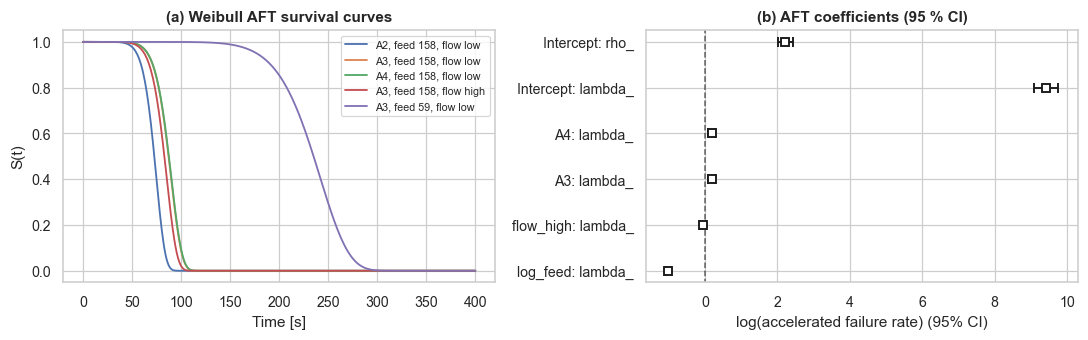

In [16]:
COV = ["log_feed", "A3", "A4", "flow_high"]
runs_tr = train_f.groupby("Data_No").agg(T=("Time", "max"), log_feed=("log_feed", "first"), A3=("A3", "first"),
                                          A4=("A4", "first"), flow_high=("flow_high", "last"))
runs_tr["E"] = sum_tr.failed.astype(int)
for r in FAILED: runs_tr.loc[r, "T"] = labels.loc[r, "T_label"]
print("STEP 1 - Weibull AFT on censored data (5 events, 45 censored)")
aft_cens = WeibullAFTFitter(penalizer=0.01).fit(runs_tr, duration_col="T", event_col="E")
aft_cens.print_summary(decimals=3)
sc = aft_cens.summary
NUM["aft_censored"] = {c: {"coef": float(sc.loc[("lambda_", c), "coef"]), "lo": float(sc.loc[("lambda_", c), "coef lower 95%"]),
                           "hi": float(sc.loc[("lambda_", c), "coef upper 95%"]), "p": float(sc.loc[("lambda_", c), "p"])} for c in COV}

runs_lab = runs_tr.copy(); runs_lab["T"] = labels.T_label; runs_lab["E"] = 1
print("STEP 2 - Model 1: Weibull AFT on the run lifetimes (observed + pseudo-labels)")
aft = WeibullAFTFitter(penalizer=0.01).fit(runs_lab, duration_col="T", event_col="E")
aft.print_summary(decimals=3)

def aft_mrl(model, X, t):
    # Weibull mean residual life for rows X at ages t.
    p = model.params_
    lam = np.exp(p.loc[("lambda_", "Intercept")] + sum(p.loc[("lambda_", c)] * X[c].values for c in COV))
    rho = np.exp(p.loc[("rho_", "Intercept")])
    z = np.minimum((np.asarray(t) / lam) ** rho, 700)
    return lam / rho * gamma(1 / rho) * gammaincc(1 / rho, z) * np.exp(z)

summ = aft.summary
NUM["aft"] = {"coef": summ["coef"].round(4).to_dict().__repr__(), "rho": float(np.exp(aft.params_.loc[("rho_", "Intercept")])),
              "b_logfeed": float(summ.loc[("lambda_", "log_feed"), "coef"]),
              "b_logfeed_ci": [float(summ.loc[("lambda_", "log_feed"), "coef lower 95%"]), float(summ.loc[("lambda_", "log_feed"), "coef upper 95%"])],
              "p": {c: float(summ.loc[("lambda_", c), "p"]) for c in COV}, "coef_lambda": {c: float(summ.loc[("lambda_", c), "coef"]) for c in COV}}

# cross-validated error against the training labels (same folds as the ML models)
cv_m1 = []
for k, (i_tr, i_va) in enumerate(gkf.split(TR, groups=groups)):
    runs_k = np.unique(groups[i_tr])
    m = WeibullAFTFitter(penalizer=0.01).fit(runs_lab.loc[runs_k], duration_col="T", event_col="E")
    va = TR.iloc[i_va]; cv_m1.append(np.sqrt(np.mean((aft_mrl(m, va, va.Time) - va.RUL) ** 2)))
print("M1 CV RMSE (vs labels):", np.round(cv_m1, 1), "mean", np.mean(cv_m1).round(1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
grid = np.linspace(0, 400, 400)
for (dust, fh, feed) in [("A2", 0, 158.5), ("A3", 0, 158.5), ("A4", 0, 158.5), ("A3", 1, 158.5), ("A3", 0, 59.1)]:
    X = pd.DataFrame({"log_feed": [np.log(feed)], "A3": [dust == "A3"], "A4": [dust == "A4"], "flow_high": [fh]}).astype(float)
    ax[0].plot(grid, aft.predict_survival_function(X, times=grid).values[:, 0], label=f"{dust}, feed {feed:.0f}, flow {'high' if fh else 'low'}")
ax[0].set(xlabel="Time [s]", ylabel="S(t)", title="(a) Weibull AFT survival curves"); ax[0].legend(fontsize=7)
aft.plot(ax=ax[1]); ax[1].set_title("(b) AFT coefficients (95 % CI)")
plt.tight_layout(); savefig("fig08_weibull_aft"); plt.show()
NUM["cv"] = {"M1 Weibull AFT": float(np.mean(cv_m1))}
TE["pred_M1"] = aft_mrl(aft, TE, TE.Time)

## 7. Model 2 – Random forest on condition features

From here on the models are **machine-learning regressors** `RUL = f(features)` trained on the 15 condition
features of Section 4, with true labels for the 5 failed runs and pseudo-labels for the 45 censored runs.

A **random forest** averages many deep decision trees, each grown on a bootstrap sample of the training data and a
random subset of features (bagging). Averaging reduces the variance of single trees; the model captures non-linear
relations and interactions (e.g. *high slope* **and** *fine dust*) without any assumption on the curve shape.

Hyper-parameters are chosen by **5-fold GroupKFold** cross-validation (folds split by *run*, so samples of the same
filter never appear in both training and validation); the best configuration is refitted on all training runs.

In [17]:
X, y = TR[FEATS].values, TR.RUL.values

def cv_rmse(mdl):
    errs = []
    for i_tr, i_va in gkf.split(X, groups=groups):
        mdl.fit(X[i_tr], y[i_tr]); errs.append(np.sqrt(np.mean((mdl.predict(X[i_va]) - y[i_va]) ** 2)))
    return np.mean(errs), np.std(errs)

def select(cands):
    tab = pd.DataFrame({n: cv_rmse(m) for n, m in cands.items()}, index=["CV RMSE", "std"]).T.sort_values("CV RMSE")
    display(tab.round(2)); best = tab.index[0]
    return best, cands[best].fit(X, y), tab

rf = lambda leaf, feat: RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, max_features=feat, n_jobs=-1, random_state=SEED)
cands_rf = {"RF leaf=5 features=0.5": rf(5, 0.5), "RF leaf=20 features=0.5": rf(20, 0.5),
            "RF leaf=5 features=1.0": rf(5, 1.0), "RF leaf=20 features=1.0": rf(20, 1.0)}
BEST_M2, m2, cv_rf = select(cands_rf)
TE["pred_M2"] = np.clip(m2.predict(TE[FEATS].values), 0, None)
print("Selected:", BEST_M2)
NUM["cv"]["M2 Random forest"] = float(cv_rf.iloc[0, 0]); NUM["m2_cv_table"] = cv_rf.round(2).to_dict(); NUM["m2_best"] = BEST_M2

,CV RMSE,std
RF leaf=20 features=1.0,13.18,5.06
RF leaf=5 features=1.0,13.33,5.81
RF leaf=5 features=0.5,13.77,3.06
RF leaf=20 features=0.5,14.80,2.00


Selected: RF leaf=20 features=1.0


## 8. Model 3 – XGBoost on condition features

**XGBoost** (eXtreme Gradient Boosting, Chen & Guestrin 2016) also combines many trees, but *sequentially*: each small
tree is fitted to the residual errors (gradients of the loss) of the trees before it, with a learning rate that shrinks
every correction (boosting mainly reduces bias, whereas the random forest mainly reduces variance). XGBoost adds L2
regularisation of the leaf weights, row and column sub-sampling and a fast histogram split search. A small grid of
depth and learning rate is selected by the same grouped cross-validation.

In [18]:
xgb = lambda depth, lr: XGBRegressor(n_estimators=400, max_depth=depth, learning_rate=lr, subsample=0.8, colsample_bytree=0.8,
                                     min_child_weight=5, reg_lambda=1.0, tree_method="hist", n_jobs=4, random_state=SEED)
cands_xgb = {"XGB depth=3 lr=0.05": xgb(3, 0.05), "XGB depth=5 lr=0.05": xgb(5, 0.05),
             "XGB depth=3 lr=0.1": xgb(3, 0.1), "XGB depth=6 lr=0.1": xgb(6, 0.1)}
BEST_M3, m3, cv_xgb = select(cands_xgb)
TE["pred_M3"] = np.clip(m3.predict(TE[FEATS].values), 0, None)
print("Selected:", BEST_M3)
NUM["cv"]["M3 XGBoost"] = float(cv_xgb.iloc[0, 0]); NUM["m3_cv_table"] = cv_xgb.round(2).to_dict(); NUM["m3_best"] = BEST_M3

,CV RMSE,std
XGB depth=3 lr=0.05,10.29,2.78
XGB depth=3 lr=0.1,10.78,2.96
XGB depth=5 lr=0.05,11.44,3.89
XGB depth=6 lr=0.1,12.39,3.10


Selected: XGB depth=3 lr=0.05


## 9. Model 4 – Recursive autoregressive model (no RUL labels)

Models 2 and 3 learn RUL **directly**, so they depend on the pseudo-labels of the 45 censored runs. Model 4 takes the
opposite route: it learns only the **dynamics of the clogging signal** and obtains the RUL by simulating the future.

1. **One-step model.** XGBoost predicts the growth of log Δp over the next 5 s,
   $y = \log(1+\Delta p_{t+5}) - \log(1+\Delta p_t)$, from the autoregressive lags
   $\log(1+\Delta p)$ at *t*, *t−5 s* and *t−10 s* (as level and two past increments), the dust load *V* and the
   settings (feed, dust grade, flow). Every observed 5-s transition of **all 50 training runs** is a valid training
   example – censoring does not matter, and **no RUL label is used** (hyper-parameters are also selected on the
   one-step error, by grouped cross-validation).
2. **Recursive roll-out.** From the current state of a filter the model is applied repeatedly, feeding its own
   predictions back as lags, in 5-s steps, until log Δp reaches log(601). The RUL is the simulated time to that
   crossing (linear interpolation inside the last step).
3. **Physical constraints.** A filter cannot unclog, so predicted increments are clipped at ≥ 0; if the simulation
   does not reach 600 Pa within 500 s, the RUL is capped at 500 s.

Predicting the *growth rate* instead of the *level* is essential: tree models cannot extrapolate levels beyond the
training range (very few training samples are above 400 Pa), whereas growth rates stay within the observed range.

In [19]:
STEP, HORIZON = 5.0, 500.0
LOG_FAIL = np.log1p(FAIL_DP)
AR_FEATS = ["logdp", "d5", "d10", "V", "log_feed", "rho", "A3", "A4", "flow_s", "flow_high"]

def ar_X(logdp, l5, l10, t, feed, rho, a3, a4, flow, fhigh):
    return np.column_stack([logdp, logdp - l5, l5 - l10, feed * t, np.log(feed), rho, a3, a4, flow, fhigh])

# one-step training set: every 1-Hz state of every training run with an observed state 5 s later
tr_ar = train_f.assign(logdp_f5=train_f.groupby("Data_No").logdp.shift(-50))
tr_ar = tr_ar[tr_ar.is_sec & (tr_ar.Time >= 1) & tr_ar.logdp_f5.notna()]
X_ar = ar_X(tr_ar.logdp, tr_ar.logdp_l5, tr_ar.logdp_l10, tr_ar.Time, tr_ar.Dust_feed, tr_ar.rho, tr_ar.A3, tr_ar.A4, tr_ar.flow_s, tr_ar.flow_high)
y_ar = (tr_ar.logdp_f5 - tr_ar.logdp).values; g_ar = tr_ar.Data_No.values
print(f"One-step training transitions: {len(y_ar)} from {len(np.unique(g_ar))} runs (all runs, censored or not)")

xgb_ar = lambda depth, lr: XGBRegressor(n_estimators=300, max_depth=depth, learning_rate=lr, subsample=0.8, colsample_bytree=0.8,
                                        min_child_weight=5, tree_method="hist", n_jobs=4, random_state=SEED)
cands_ar = {"AR-XGB depth=3 lr=0.05": xgb_ar(3, 0.05), "AR-XGB depth=5 lr=0.05": xgb_ar(5, 0.05),
            "AR-XGB depth=3 lr=0.1": xgb_ar(3, 0.1), "AR-XGB depth=6 lr=0.1": xgb_ar(6, 0.1)}
res_ar = {}
for n, mdl in cands_ar.items():
    e = []
    for i_tr, i_va in gkf.split(X_ar, groups=g_ar):
        mdl.fit(X_ar[i_tr], y_ar[i_tr]); e.append(np.sqrt(np.mean((mdl.predict(X_ar[i_va]) - y_ar[i_va]) ** 2)))
    res_ar[n] = (np.mean(e), np.std(e))
cv_ar = pd.DataFrame(res_ar, index=["CV one-step RMSE (log units)", "std"]).T.sort_values("CV one-step RMSE (log units)")
display(cv_ar.round(4))
naive = np.sqrt(np.mean((y_ar - 0) ** 2)); persist = np.sqrt(np.mean((y_ar - X_ar[:, 1]) ** 2))
print(f"Reference one-step errors: zero growth {naive:.4f}, 'same growth as last 5 s' {persist:.4f}")
BEST_M4 = cv_ar.index[0]; m4 = cands_ar[BEST_M4].fit(X_ar, y_ar)
print("Selected:", BEST_M4)

def ar_rollout(model, df):
    # Recursive simulation from every row of df (its current state) until log Δp reaches log(601).
    logdp, l5, l10 = df.logdp.values.copy(), df.logdp_l5.values.copy(), df.logdp_l10.values.copy()
    t0 = df.Time.values.astype(float); t = t0.copy()
    stat = [df[c].values for c in ["Dust_feed", "rho", "A3", "A4", "flow_s", "flow_high"]]
    rul = np.full(len(df), np.nan); active = logdp < LOG_FAIL; rul[~active] = 0.0
    for _ in range(int(HORIZON / STEP)):
        idx = np.where(active)[0]
        if len(idx) == 0: break
        X = ar_X(logdp[idx], l5[idx], l10[idx], t[idx], *[v[idx] for v in stat])
        new = logdp[idx] + np.clip(model.predict(X), 0, None)
        cross = new >= LOG_FAIL
        c = idx[cross]
        frac = (LOG_FAIL - logdp[c]) / np.maximum(new[cross] - logdp[c], 1e-9)
        rul[c] = t[c] - t0[c] + STEP * frac
        l10[idx], l5[idx], logdp[idx], t[idx] = l5[idx], logdp[idx], new, t[idx] + STEP
        active[c] = False
    capped = np.isnan(rul); rul[capped] = HORIZON
    return rul, capped

TR = TR.sort_values(["Data_No", "Time"]); TE = TE.sort_values(["Data_No", "Time"])
t0 = time.time()
TE["pred_M4"], cap_te = ar_rollout(m4, TE)
print(f"Roll-out from {len(TE)} test states in {time.time()-t0:.1f} s; capped at {HORIZON:.0f} s: {cap_te.mean()*100:.1f} %")
NUM["cv"]["M4 Autoregressive (one-step, log units)"] = float(cv_ar.iloc[0, 0]); NUM["m4_cv_table"] = cv_ar.round(4).to_dict()
NUM["m4_best"] = BEST_M4; NUM["m4_cap_share"] = float(cap_te.mean()); NUM["m4_n_transitions"] = int(len(y_ar))
NUM["m4_onestep_ref"] = {"zero growth": float(naive), "last growth": float(persist)}

One-step training transitions: 3657 from 50 runs (all runs, censored or not)


,CV one-step RMSE (log units),std
AR-XGB depth=3 lr=0.05,0.2535,0.0188
AR-XGB depth=3 lr=0.1,0.2634,0.0242
AR-XGB depth=5 lr=0.05,0.2662,0.0280
AR-XGB depth=6 lr=0.1,0.2835,0.0295


Reference one-step errors: zero growth 0.4649, 'same growth as last 5 s' 0.5238


Selected: AR-XGB depth=3 lr=0.05


Roll-out from 3963 test states in 3.3 s; capped at 500 s: 0.0 %


**Illustration on a held-out training run.** To show how the roll-out behaves without touching the test set, the
one-step model is refitted without failed training run 43 and the simulation is started from three instants of that run.

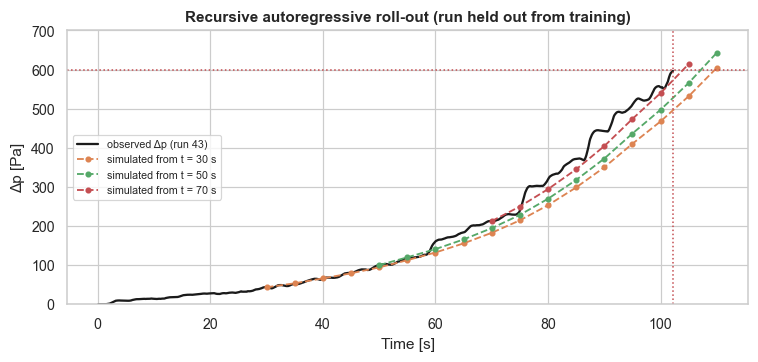

In [20]:
demo_run = 43
m4_demo = cands_ar[BEST_M4].__class__(**cands_ar[BEST_M4].get_params()).fit(X_ar[g_ar != demo_run], y_ar[g_ar != demo_run])
d = train_f[train_f.Data_No == demo_run]
fig, ax = plt.subplots(figsize=(7, 3.4))
sns.lineplot(x=d.Time, y=d.dp_s, color="k", lw=1.5, label="observed Δp (run 43)", ax=ax)
for k, ts in enumerate([30, 50, 70]):
    row = d[np.isclose(d.Time, ts)].iloc[[0]]
    lg, a5, a10, tt = row.logdp.values.copy(), row.logdp_l5.values.copy(), row.logdp_l10.values.copy(), float(ts)
    path_t, path_p = [tt], [np.expm1(lg[0])]
    st = [row[c].values for c in ["Dust_feed", "rho", "A3", "A4", "flow_s", "flow_high"]]
    while lg[0] < LOG_FAIL and tt < ts + HORIZON:
        new = lg + np.clip(m4_demo.predict(ar_X(lg, a5, a10, np.array([tt]), *st)), 0, None)
        a10, a5, lg, tt = a5, lg, new, tt + STEP
        path_t.append(tt); path_p.append(np.expm1(lg[0]))
    ax.plot(path_t, path_p, "--o", ms=3, color=PAL[k + 1], label=f"simulated from t = {ts} s")
ax.axhline(FAIL_DP, color="r", ls=":", lw=1)
T_fail_demo = d.Time.values[np.argmax(d.dp_raw.values >= FAIL_DP)]
ax.axvline(T_fail_demo, color="r", ls=":", lw=1)
ax.set(xlabel="Time [s]", ylabel="Δp [Pa]", title="Recursive autoregressive roll-out (run held out from training)", ylim=(0, 700))
ax.legend(fontsize=7)
plt.tight_layout(); savefig("fig09_ar_rollout"); plt.show()

## 10. Test-set comparison

The test set is used **only here**. Two views:
1. **Primary – RUL at the last observed sample** of each of the 50 test runs (the task defined by the dataset):
   RMSE, MAE, bias (mean of predicted − true; positive = optimistic), share of predictions within ±10 s, and the
   asymmetric **PHM08 score** `s = Σ (e^{-d/13} − 1)` for early (d < 0) and `Σ (e^{d/10} − 1)` for late (d > 0)
   predictions, `d = RÛL − RUL`: late (optimistic) predictions are penalised more because they cause unplanned failures.
2. **Secondary – all test samples (1 Hz)**: RMSE as a function of the true RUL (prediction horizon).

In [21]:
MODELS = {"M1 Weibull AFT": "pred_M1", "M2 Random forest": "pred_M2", "M3 XGBoost": "pred_M3", "M4 Autoregressive": "pred_M4"}

def phm_score(d): return np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1))
def metrics(pred, true):
    d = pred - true
    return {"RMSE": np.sqrt(np.mean(d**2)), "MAE": np.mean(np.abs(d)), "Bias": np.mean(d),
            "Within ±10 s [%]": np.mean(np.abs(d) <= 10) * 100, "PHM score": phm_score(d)}

LAST = TE[TE.is_last]
res_last = pd.DataFrame({m: metrics(LAST[c].values, LAST.RUL.values) for m, c in MODELS.items()}).T
res_all = pd.DataFrame({m: metrics(TE[c].values, TE.RUL.values) for m, c in MODELS.items()}).T
print("Primary evaluation – last observed sample of each test run (n = 50)"); display(res_last.round(2))
print("Secondary evaluation – all test samples at 1 Hz"); display(res_all[["RMSE", "MAE", "Bias"]].round(2))
res_last.to_csv("results/test_metrics_last.csv"); res_all.to_csv("results/test_metrics_all.csv")
TE[["Data_No", "Time", "RUL"] + list(MODELS.values())].to_csv("results/test_predictions.csv", index=False)
NUM["test_last"] = res_last.round(3).to_dict(orient="index"); NUM["test_all"] = res_all.round(3).to_dict(orient="index")
BEST = res_last.RMSE.idxmin(); NUM["best_model"] = BEST; print("Best model (RMSE, last sample):", BEST)

# Paired bootstrap over the 50 test runs: is the RMSE difference between two models significant?
rng_b = np.random.default_rng(SEED); B = 5000
err = {m: LAST[c].values - LAST.RUL.values for m, c in MODELS.items()}
idx = rng_b.integers(0, len(LAST), (B, len(LAST)))
def boot(a, b):   # RMSE(a) - RMSE(b); positive = b is better
    d = np.sqrt((err[a][idx] ** 2).mean(1)) - np.sqrt((err[b][idx] ** 2).mean(1))
    lo, hi = np.percentile(d, [2.5, 97.5]); return {"diff": float(np.sqrt((err[a]**2).mean()) - np.sqrt((err[b]**2).mean())), "lo": float(lo), "hi": float(hi), "significant": bool(lo > 0 or hi < 0)}
ML = ["M2 Random forest", "M3 XGBoost", "M4 Autoregressive"]
pairs = [("M1 Weibull AFT", m) for m in ML] + [("M2 Random forest", "M3 XGBoost"), ("M2 Random forest", "M4 Autoregressive"), ("M3 XGBoost", "M4 Autoregressive")]
boot_tab = pd.DataFrame({f"{a} − {b}": boot(a, b) for a, b in pairs}).T
print("Paired bootstrap of RMSE differences (last sample, 95 % CI):"); display(boot_tab)
NUM["bootstrap"] = boot_tab.to_dict(orient="index")

Primary evaluation – last observed sample of each test run (n = 50)


,RMSE,MAE,Bias,Within ±10 s [%],PHM score
M1 Weibull AFT,24.26,17.06,-11.49,46.0,790.84
M2 Random forest,19.50,13.79,-5.87,52.0,682.98
M3 XGBoost,18.78,13.34,-10.73,54.0,320.78
M4 Autoregressive,15.19,10.89,-9.35,62.0,160.97


Secondary evaluation – all test samples at 1 Hz


,RMSE,MAE,Bias
M1 Weibull AFT,46.85,36.51,-32.93
M2 Random forest,40.30,31.59,-28.59
M3 XGBoost,38.30,30.09,-29.10
M4 Autoregressive,26.59,21.48,-17.26


Best model (RMSE, last sample): M4 Autoregressive
Paired bootstrap of RMSE differences (last sample, 95 % CI):


,diff,lo,hi,significant
M1 Weibull AFT − M2 Random forest,4.768563,-1.755029,10.796156,False
M1 Weibull AFT − M3 XGBoost,5.485698,1.003146,9.871104,True
M1 Weibull AFT − M4 Autoregressive,9.069912,3.736054,14.84409,True
M2 Random forest − M3 XGBoost,0.717135,-2.289123,4.91805,False
M2 Random forest − M4 Autoregressive,4.301349,0.595789,8.844096,True
M3 XGBoost − M4 Autoregressive,3.584214,1.389384,5.699366,True


### 10.0 Run-by-run comparison with the ground truth
The test file provides the true RUL of every sample (`RUL` column). The table below lists, for each of the 50 test runs,
its settings, the time at which it was truncated, the **ground-truth RUL** at that instant and the prediction and
error (predicted − true) of every model. It is also saved as `results/test_ground_truth_comparison.csv`.

,Run,Dust,Feed [mm³/s],Flow,t_last [s],True RUL [s],M1 pred,M1 error,M2 pred,M2 error,M3 pred,M3 error,M4 pred,M4 error
0,4,A3,317.0,56.0,60.9,1.9,0.4,-1.5,4.7,2.8,0.000000,-1.9,1.0,-0.9
1,41,A2,237.7,80.5,49.9,2.1,2.6,0.5,4.7,2.6,0.000000,-2.1,1.3,-0.8
2,3,A3,317.0,55.6,56.4,3.6,0.7,-2.9,4.7,1.1,0.000000,-3.6,1.1,-2.5
3,39,A2,177.3,82.8,31.5,5.1,29.4,24.3,11.2,6.1,11.800000,6.7,7.0,1.9
4,18,A3,59.1,81.8,257.9,5.3,8.5,3.2,65.0,59.7,26.299999,21.0,6.3,1.0
5,17,A3,59.1,81.6,193.4,6.0,36.5,30.5,22.1,16.1,10.400000,4.4,4.7,-1.3
6,42,A2,236.4,59.4,40.3,6.6,9.2,2.6,9.9,3.3,4.100000,-2.5,6.0,-0.6
7,8,A3,158.5,58.1,114.5,7.3,1.4,-5.9,24.1,16.8,0.200000,-7.1,2.1,-5.2
8,50,A4,317.0,82.5,52.4,7.8,0.9,-6.9,8.0,0.2,0.400000,-7.4,1.7,-6.1
9,43,A2,236.4,80.8,17.6,8.6,28.0,19.4,19.5,10.9,17.600000,9.0,13.7,5.1


Number of test runs where each model is the closest to the ground truth:


M4    20
M2    14
M1    10
M3     6
Name: count, dtype: int64

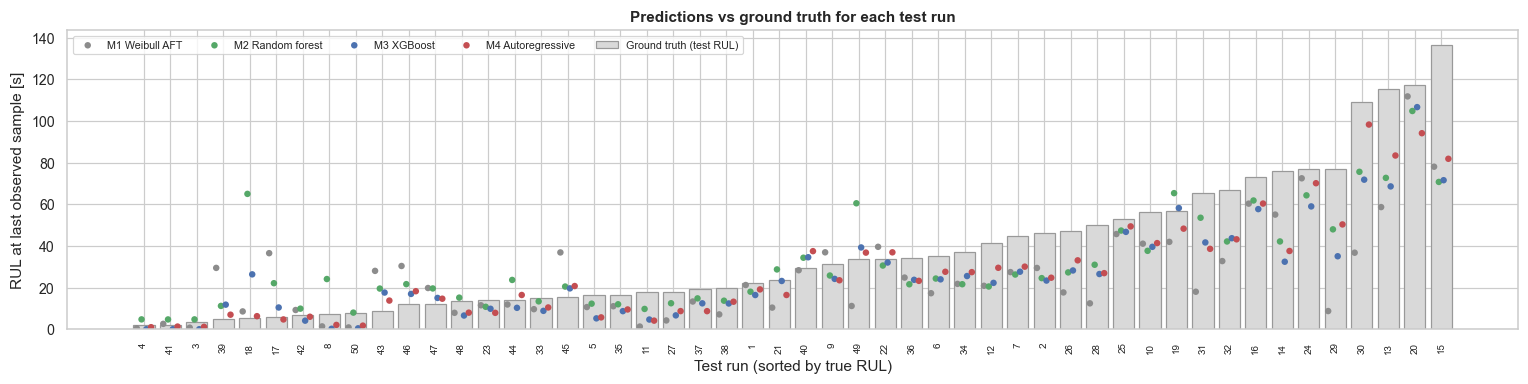

In [22]:
gt = LAST[["Data_No", "DustCode", "Dust_feed", "flow_s", "Time", "RUL"]].copy()
gt.columns = ["Run", "Dust", "Feed [mm³/s]", "Flow", "t_last [s]", "True RUL [s]"]
for m, c in MODELS.items():
    k = m.split()[0]
    gt[f"{k} pred"] = LAST[c].values; gt[f"{k} error"] = LAST[c].values - LAST.RUL.values
gt = gt.sort_values("True RUL [s]").reset_index(drop=True)
gt.round(1).to_csv("results/test_ground_truth_comparison.csv", index=False)
display(gt.round(1))
best_run = gt[[f"{m.split()[0]} error" for m in MODELS]].abs().idxmin(axis=1).str.split().str[0].value_counts()
print("Number of test runs where each model is the closest to the ground truth:"); display(best_run)
NUM["closest_model_count"] = best_run.to_dict()

fig, ax = plt.subplots(figsize=(14, 3.6))
x = np.arange(len(gt))
ax.bar(x, gt["True RUL [s]"], width=.8, color="0.85", edgecolor="0.6", label="Ground truth (test RUL)")
off = {"M1": -0.27, "M2": -0.09, "M3": 0.09, "M4": 0.27}
for m in MODELS:
    k = m.split()[0]
    sns.scatterplot(x=x + off[k], y=gt[f"{k} pred"].values, s=18, color=MODEL_COL[m], edgecolor="none", label=m, ax=ax)
ax.set_xticks(x, gt.Run.astype(str), fontsize=6.5, rotation=90)
ax.set(xlabel="Test run (sorted by true RUL)", ylabel="RUL at last observed sample [s]", title="Predictions vs ground truth for each test run")
ax.legend(fontsize=7, ncol=5, loc="upper left")
plt.tight_layout(); savefig("fig15_ground_truth_by_run"); plt.show()

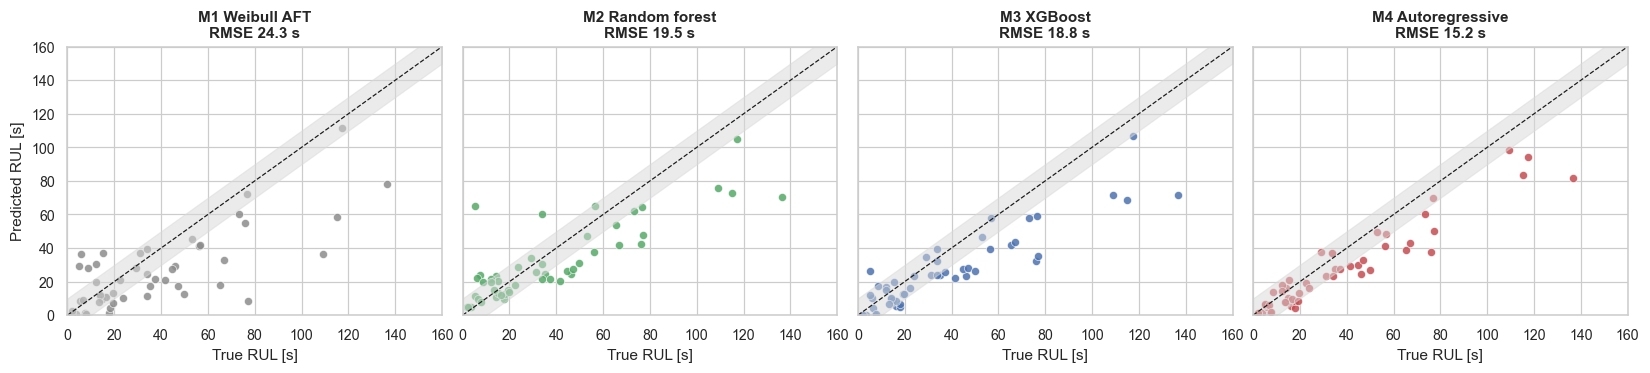

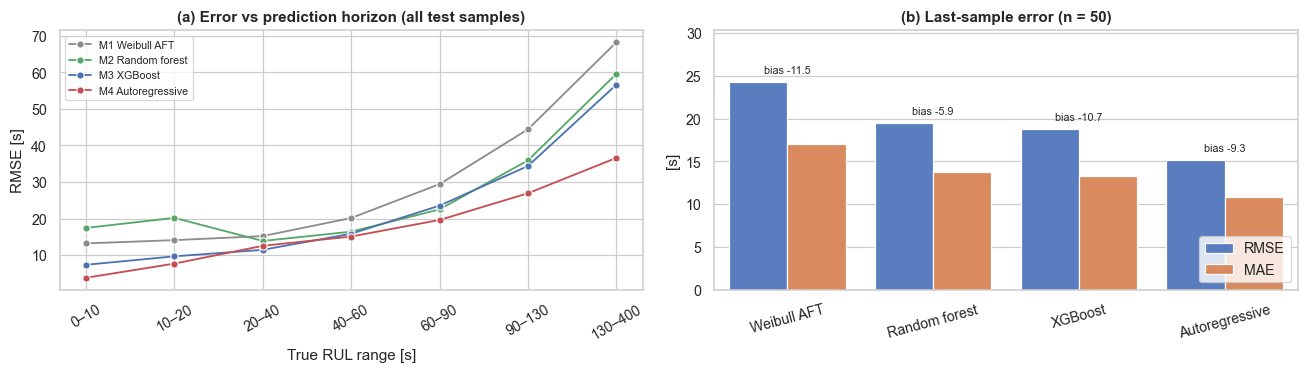

In [23]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.5), sharex=True, sharey=True)
lim = 160
for a, (m, c) in zip(ax, MODELS.items()):
    sns.scatterplot(x=LAST.RUL.values, y=LAST[c].values, s=28, color=MODEL_COL[m], alpha=.85, edgecolor="white", ax=a)
    a.plot([0, lim], [0, lim], "k--", lw=.8); a.fill_between([0, lim], [-10, lim - 10], [10, lim + 10], color="0.85", alpha=.5)
    a.set(xlim=(0, lim), ylim=(0, lim), xlabel="True RUL [s]", title=f"{m}\nRMSE {res_last.loc[m,'RMSE']:.1f} s")
ax[0].set_ylabel("Predicted RUL [s]")
plt.tight_layout(); savefig("fig10_pred_vs_true"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
bins = [0, 10, 20, 40, 60, 90, 130, 400]
TE["hbin"] = pd.cut(TE.RUL, bins)
hz = pd.DataFrame([{"model": m, "bin": i, "RMSE": np.sqrt(np.mean((d[c] - d.RUL) ** 2))}
                   for m, c in MODELS.items() for i, (_, d) in enumerate(TE.groupby("hbin", observed=False))])
sns.lineplot(data=hz, x="bin", y="RMSE", hue="model", palette=MODEL_COL, marker="o", ax=ax[0])
ax[0].set_xticks(range(len(bins) - 1), [f"{a}–{b}" for a, b in zip(bins[:-1], bins[1:])], rotation=30)
ax[0].set(xlabel="True RUL range [s]", ylabel="RMSE [s]", title="(a) Error vs prediction horizon (all test samples)"); ax[0].legend(fontsize=7)
lm = res_last[["RMSE", "MAE"]].rename_axis("model").reset_index().melt(id_vars="model", var_name="metric", value_name="value")
lm["model"] = lm.model.str.split(" ", n=1).str[1]
sns.barplot(data=lm, x="model", y="value", hue="metric", palette="muted", ax=ax[1])
for i, v in enumerate(res_last.Bias): ax[1].text(i, res_last.RMSE.iloc[i] + 1, f"bias {v:+.1f}", ha="center", fontsize=7)
ax[1].tick_params(axis="x", rotation=15)
ax[1].set(xlabel="", ylabel="[s]", title="(b) Last-sample error (n = 50)", ylim=(0, res_last.RMSE.max() * 1.25)); ax[1].legend(loc="lower right")
plt.tight_layout(); savefig("fig11_error_horizon"); plt.show()

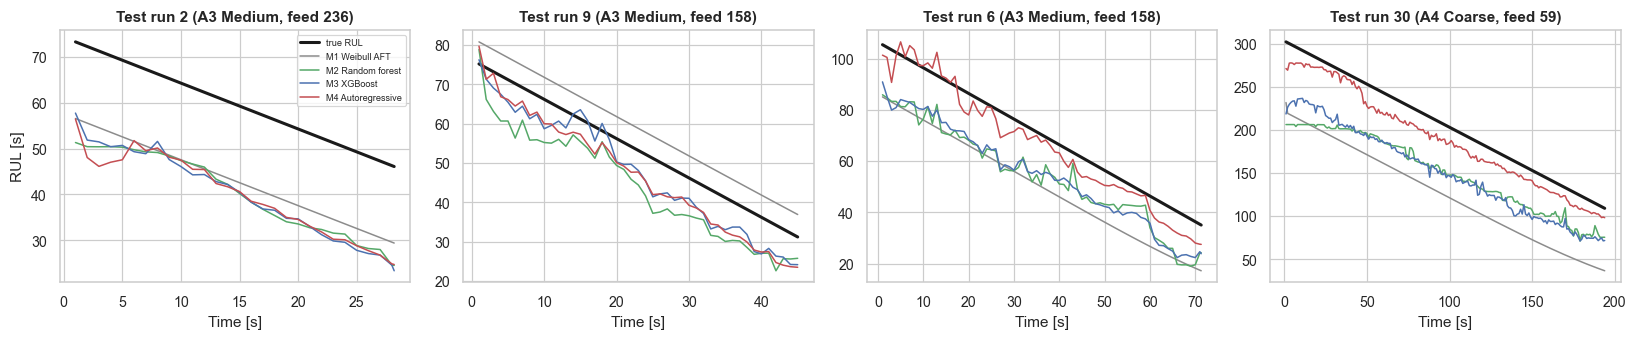

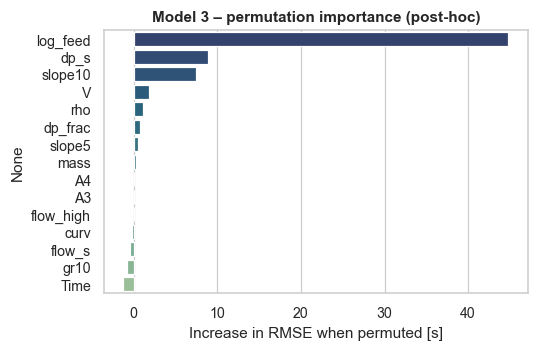

In [24]:
show = list(sum_te.sort_values("t_end").index[[8, 20, 32, 45]])
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for a, r in zip(ax, show):
    d = TE[TE.Data_No == r]
    a.plot(d.Time, d.RUL, "k", lw=2, label="true RUL")
    for m, c in MODELS.items(): a.plot(d.Time, d[c], color=MODEL_COL[m], lw=1, label=m)
    a.set(xlabel="Time [s]", title=f"Test run {r} ({DUST_NAME[d.DustCode.iloc[0]]}, feed {d.Dust_feed.iloc[0]:.0f})")
ax[0].set_ylabel("RUL [s]"); ax[0].legend(fontsize=6)
plt.tight_layout(); savefig("fig12_rul_trajectories"); plt.show()

pi = permutation_importance(m3, TE[FEATS].values, TE.RUL.values, n_repeats=5, random_state=SEED, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(5, 3.3))
sns.barplot(x=imp.values[::-1], y=imp.index[::-1], hue=imp.index[::-1], palette="crest_r", legend=False, ax=ax)
ax.set(xlabel="Increase in RMSE when permuted [s]", title="Model 3 – permutation importance (post-hoc)")
plt.tight_layout(); savefig("fig13_importance"); plt.show()
NUM["m3_importance"] = imp.sort_values(ascending=False).round(2).to_dict()

### 10.1 What the predictions mean for maintenance (supporting analysis)

To translate accuracy into the business objective (not a formal hypothesis) we compare, on the 50 test filters (whose true failure time
`T_fail = t_last + RUL_last` is known), the **current preventive policy** – replace when the dust fed reaches
V ≈ 10 600 mm³ – with a **predictive policy** that, at the last observed sample, schedules the replacement at
`t_last + RÛL`.
For each policy: number of **unplanned failures** (filter clogs before the replacement) and **wasted life**
(`T_fail − t_replace` for filters replaced before failure).

,Unplanned failures,Mean wasted life [s],Life used [%]
Preventive (V = 10 600 mm³),5.0,40.8,72.4
Predictive – M1 Weibull AFT,11.0,18.3,89.5
Predictive – M2 Random forest,19.0,15.9,92.5
Predictive – M3 XGBoost,10.0,15.0,90.1
Predictive – M4 Autoregressive,10.0,12.6,91.5


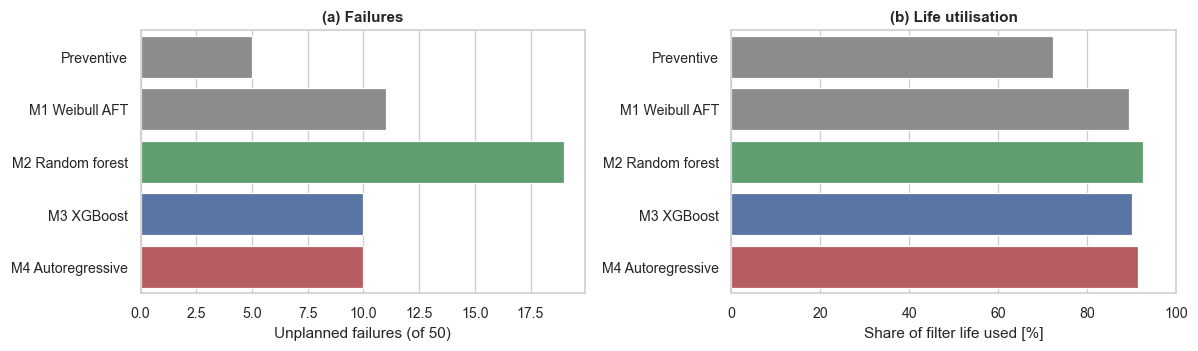

In [25]:
pol = sum_te[["t_end", "feed", "RUL_last"]].copy(); pol["T_fail"] = pol.t_end + pol.RUL_last
def policy(t_rep):
    fail = t_rep > pol.T_fail
    waste = np.where(fail, 0, pol.T_fail - t_rep)
    return {"Unplanned failures": int(fail.sum()), "Mean wasted life [s]": float(waste[~fail].mean()),
            "Life used [%]": float(np.mean(np.minimum(t_rep, pol.T_fail) / pol.T_fail) * 100)}
rows = {"Preventive (V = 10 600 mm³)": policy(NUM["V_censor"] / pol.feed)}
lastp = LAST.set_index("Data_No")
for m, c in MODELS.items():
    rows[f"Predictive – {m}"] = policy(pol.t_end + lastp.loc[pol.index, c])
pol_tab = pd.DataFrame(rows).T; display(pol_tab.round(1)); pol_tab.to_csv("results/maintenance_policy.csv")
NUM["policy"] = pol_tab.round(2).to_dict(orient="index")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
lab = [k.replace("Predictive – ", "").replace(" (V = 10 600 mm³)", "") for k in pol_tab.index]
pcol = [PAL[7]] + [MODEL_COL[m] for m in MODELS]
sns.barplot(x=pol_tab["Unplanned failures"].values, y=lab, hue=lab, palette=pcol, legend=False, ax=ax[0])
ax[0].set(xlabel="Unplanned failures (of 50)", title="(a) Failures")
sns.barplot(x=pol_tab["Life used [%]"].values, y=lab, hue=lab, palette=pcol, legend=False, ax=ax[1])
ax[1].set(xlabel="Share of filter life used [%]", title="(b) Life utilisation", xlim=(0, 100))
plt.tight_layout(); savefig("fig14_policy"); plt.show()

### 10.2 Imminent-failure alarm view
The reference Kaggle notebook on this dataset evaluates a *near-failure* classification with a confusion matrix.
The same idea can be derived from any RUL model: raise an **alarm when RÛL ≤ 15 s** and compare with the truth
(RUL ≤ 15 s) on all test samples. Recall = share of imminent failures detected; precision = share of alarms that were justified.

In [26]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
H_ALARM = 15
truth = TE.RUL <= H_ALARM
alarm = {m: {"Precision": precision_score(truth, TE[c] <= H_ALARM), "Recall": recall_score(truth, TE[c] <= H_ALARM),
             "F1": f1_score(truth, TE[c] <= H_ALARM)} for m, c in MODELS.items()}
alarm = pd.DataFrame(alarm).T; display(alarm.round(3))
cm = confusion_matrix(truth, TE[MODELS[BEST]] <= H_ALARM)
print(f"Confusion matrix of {BEST} (rows: true OK / imminent, cols: predicted OK / alarm):\n", cm)
NUM["alarm"] = alarm.round(3).to_dict(orient="index"); NUM["alarm_cm_best"] = cm.tolist()

,Precision,Recall,F1
M1 Weibull AFT,0.239,0.697,0.355
M2 Random forest,0.400,0.454,0.425
M3 XGBoost,0.305,0.655,0.416
M4 Autoregressive,0.355,0.815,0.495


Confusion matrix of M4 Autoregressive (rows: true OK / imminent, cols: predicted OK / alarm):
 [[3668  176]
 [  22   97]]


### 10.3 Comparison with the reference notebook approach
The reference notebook *"Predictive maintenance using ML and LSTM RNN"* (Kaggle) frames the problem as forecasting
**Δp 10 samples (1 s) ahead** from the last 20 samples and reports R² ≈ 0.996 / MAE ≈ 4.5 Pa for linear regression,
random forest, SVR, KNN and an LSTM. We reproduce that set-up with linear regression (windows built per run, trained on
the training runs only) and compare it with a **naive persistence forecast** (Δp(t+1 s) = Δp(t)).

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
def windows(df, L=20, H=10):
    X, Y = [], []
    for _, d in df.groupby("Data_No"):
        a = d.Differential_pressure.values
        for s in range(0, len(a) - L - H):
            X.append(a[s:s + L]); Y.append(a[s + L + H - 1])
    return np.array(X), np.array(Y)
Xw_tr, yw_tr = windows(train_c); Xw_te, yw_te = windows(test_c)
lr = LinearRegression().fit(Xw_tr, yw_tr)
ref = pd.DataFrame({
    "Linear regression (reference set-up)": [mean_absolute_error(yw_te, lr.predict(Xw_te)), r2_score(yw_te, lr.predict(Xw_te))],
    "Naive persistence Δp(t+1s)=Δp(t)": [mean_absolute_error(yw_te, Xw_te[:, -1]), r2_score(yw_te, Xw_te[:, -1])]},
    index=["MAE [Pa]", "R²"]).T
display(ref.round(4))
NUM["reference_replication"] = ref.round(4).to_dict(orient="index")

,MAE [Pa],R²
Linear regression (reference set-up),4.4137,0.9968
Naive persistence Δp(t+1s)=Δp(t),4.4119,0.9960


A 1-second-ahead forecast of Δp is almost as good with the trivial persistence rule as with any model, because Δp
changes very little in one second. The high R² reported in the reference therefore does not measure the ability to
anticipate failure: it does not answer *how many seconds remain until 600 Pa*, and it does not deal with the
censoring of the training data. This is why our project models **RUL directly** and evaluates it at the truncation
point of each test run.

## 11. Hypotheses and export

| | Hypothesis | Test |
|---|---|---|
| H1 | Condition monitoring (Δp) improves RUL prediction over a reliability model that only knows the settings | ML models M2–M4 vs M1, test RMSE (last sample); accepted if the paired-bootstrap 95 % CI of the difference excludes 0 for at least one model |
| H2 | Dust feed and dust grade are the dominant drivers of filter life (life ∝ 1/feed) | Weibull AFT: significance of the coefficients, β(log feed) ≈ −1 |
| H3 | The recursive autoregressive model (M4), trained without any RUL label, outperforms the direct RUL regressors trained on pseudo-labels (M2, M3) | test RMSE (last sample); accepted if M4 is significantly better than both |

In [28]:
r = res_last.RMSE
b = NUM["aft"]
H = {
 "H1": (any(boot_tab.loc[f"M1 Weibull AFT − {m}", "lo"] > 0 for m in ML),
        f"best ML RMSE {min(r[m] for m in ML):.1f} s vs {r['M1 Weibull AFT']:.1f} s for the Weibull AFT; "
        + "; ".join(f"M1−{m.split()[0]}: {boot_tab.loc[f'M1 Weibull AFT − {m}', 'diff']:+.1f} s [{boot_tab.loc[f'M1 Weibull AFT − {m}', 'lo']:+.1f}, {boot_tab.loc[f'M1 Weibull AFT − {m}', 'hi']:+.1f}]" for m in ML)),
 "H2": (b["p"]["log_feed"] < 0.05 and b["b_logfeed_ci"][0] <= -1 <= b["b_logfeed_ci"][1],
        f"beta(log feed) = {b['b_logfeed']:.2f} (95% CI {b['b_logfeed_ci'][0]:.2f} to {b['b_logfeed_ci'][1]:.2f}), p = {b['p']['log_feed']:.3g}; "
        f"p(A3) = {b['p']['A3']:.3g}, p(A4) = {b['p']['A4']:.3g}, p(flow) = {b['p']['flow_high']:.3g}"),
 "H3": (all(boot_tab.loc[f"{m} − M4 Autoregressive", "lo"] > 0 for m in ["M2 Random forest", "M3 XGBoost"]),
        f"M4 {r['M4 Autoregressive']:.1f} s vs M2 {r['M2 Random forest']:.1f} s and M3 {r['M3 XGBoost']:.1f} s; "
        + "; ".join(f"{m.split()[0]}−M4: {boot_tab.loc[f'{m} − M4 Autoregressive', 'diff']:+.1f} s [{boot_tab.loc[f'{m} − M4 Autoregressive', 'lo']:+.1f}, {boot_tab.loc[f'{m} − M4 Autoregressive', 'hi']:+.1f}]" for m in ["M2 Random forest", "M3 XGBoost"])),
}
hyp = pd.DataFrame({k: {"Result": "accepted" if v[0] else "rejected", "Evidence": v[1]} for k, v in H.items()}).T
display(hyp)
NUM["hypotheses"] = hyp.to_dict(orient="index")
with open("results/numbers.json", "w", encoding="utf-8") as f:
    json.dump(NUM, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("results/numbers.json written with", len(NUM), "entries")

,Result,Evidence
H1,accepted,best ML RMSE 15.2 s vs 24.3 s for the Weibull ...
H2,accepted,beta(log feed) = -1.00 (95% CI -1.08 to -0.93)...
H3,accepted,M4 15.2 s vs M2 19.5 s and M3 18.8 s; M2−M4: +...


results/numbers.json written with 50 entries
